# §10 Synthesis and Interpretation (Stage S10)

§1–§9 produced numbers; this section turns them into **claims** with an honest strength, scope and
falsifier. Nothing here is re-estimated: every value is read from the stored results of the earlier
sections (`results/metrics_S*.json`, `results/S*/`), and every number shown on a slide is re-read and
asserted at the end. The machine-learning models are treated as **measuring instruments** – a leak
detector, a coefficient-stability meter, a label-bias meter, a negative control – so the question is not
"how good is the model?" but "what did the models reveal about the data?".

Contents: 1 inputs · 2 hypothesis scoreboard · 3 post-lock notes · 4 improvements and deteriorations ·
5 what the ML evidence says about the data · 6 headline findings · 7 claims ledger · 8 hold-out against
cross-validation · 9 limitations · 10 ethics, governance and recommendations · 11 numbers on slides ·
12 register and storage

Vocabulary. Verdicts follow the locked rules of `governance/hypotheses.md` (supported / refuted /
equivalent / inconclusive / mixed). Evidence grades: **E1** deterministic fact (a count), **E2** large
effect whose CI excludes 0 and that is stable under §9's checks, **E3** moderate effect or sensitive to a
choice, **E4** exploratory. The wording of a claim follows its grade: E1 *confirms*, E2 *shows*, E3 *is
consistent with*, E4 *suggests*. Statements say *association*, never *cause*.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as ek

pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 70)
OUT = C.RESULTS_DIR / "S10"
OUT.mkdir(parents=True, exist_ok=True)
OI = C.OKABE_ITO
T_START = time.time()
SECTIONS = ("S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9")
SEC = {"S1": "§1", "S2": "§1", "S3": "§2", "S4": "§4", "S5": "§5", "S6": "§6", "S7": "§7", "S8": "§8", "S9": "§9", "S10": "§10"}
S10 = {"mode": C.NB_MODE}
print(f"mode {C.NB_MODE}; this section re-estimates nothing – it reads stored results only")

mode FAST; this section re-estimates nothing – it reads stored results only


## 1 Inputs and provenance
**Why.** A synthesis is only as good as its inputs: it must read the results of the run that produced the
notebook, from the locked hypothesis file, and say which run mode each section came from.

The helper `get("S7:headline.leak_gate_T1_eall.est")` resolves a *source key* – section, then a dotted path
into that section's metrics file; `name[k=v&k2=v2]` picks the one record of a list that matches. The same
keys are written next to every slide number in §10.11, so each number can be traced to its origin.

In [2]:
M = {s: R.load_section(s) for s in SECTIONS}
modes = {s: M[s]["_meta"]["nb_mode"] for s in SECTIONS}
print("run mode per section:", modes)
if C.IS_FINAL:   # numbers that depend on resampling size must come from the full protocol
    assert all(modes[s] == "FINAL" for s in ("S7", "S8", "S9")), modes

_SPLIT = re.compile(r"\.(?![^\[]*\])")


def _match(v, want: str) -> bool:
    try:
        return abs(float(v) - float(want)) < 1e-9
    except (TypeError, ValueError):
        return str(v) == want


def get(key: str, src: dict | None = None):
    """Resolve 'S7:path.to[k=v&k2=v2].value' in the metrics dictionaries (default: this run's M)."""
    sec, path = key.split(":", 1)
    d = (src or M)[sec]
    for seg in _SPLIT.split(path):
        m = re.fullmatch(r"([^\[]*)(?:\[(.*)\])?", seg)
        name, filt = m.group(1), m.group(2)
        if name:
            d = d[name]
        if filt:
            conds = [c.split("=", 1) for c in filt.split("&")]
            hits = [x for x in d if all(_match(x.get(k), v) for k, v in conds)]
            assert len(hits) == 1, f"{key}: {len(hits)} records match [{filt}]"
            d = hits[0]
    return d


# hypotheses.md is locked: its SHA-256 must equal the pre-registration record of §6
hyp_bytes = (C.GOVERNANCE_DIR / "hypotheses.md").read_bytes()
hyp_sha = hashlib.sha256(hyp_bytes).hexdigest()
lock = get("S6:hypotheses.lock")
assert hyp_sha == lock["sha256"], "governance/hypotheses.md differs from the locked version"
print(f"hypotheses.md SHA-256 {hyp_sha[:16]}... equals the lock of {lock['timestamp']} (commit {lock['commit'][:10]}); "
      f"first experiment commit {lock['first_exp_timestamp']} is later: {lock['first_exp_timestamp'] > lock['timestamp']}")

# parse the locked hypothesis tables (statement, metric, direction, magnitude, SESOI, falsifier, prior exposure)
HCOLS = ["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
rows = []
for line in hyp_bytes.decode("utf-8").splitlines():
    if line.startswith("| ") and not line.startswith("| hyp_id") and not line.startswith("|---"):
        cells = [c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", line.strip().strip("|"))]
        if len(cells) == len(HCOLS):
            rows.append(dict(zip(HCOLS, cells)))
HYP = pd.DataFrame(rows).set_index("hyp_id")
HYP["prior"] = HYP["prior_exposure"].str.split(" ").str[0]
assert len(HYP) == M["S6"]["hypotheses"]["n_total"] == 17, len(HYP)
print(f"{len(HYP)} locked hypotheses parsed; prior exposure: {HYP['prior'].value_counts().to_dict()}")

run mode per section: {'S1': 'FAST', 'S2': 'FAST', 'S3': 'FAST', 'S4': 'FAST', 'S5': 'FAST', 'S6': 'FAST', 'S7': 'FINAL', 'S8': 'FINAL', 'S9': 'FINAL'}
hypotheses.md SHA-256 de032f4d200fa1ff... equals the lock of 2026-10-11T02:17:18+08:00 (commit 9fb6aefd8a); first experiment commit 2026-10-11T02:34:13+08:00 is later: True
17 locked hypotheses parsed; prior exposure: {'none': 6, 'analysis_seen': 5, 'descriptive_seen': 4, 'prototype_seen': 2}


**So what.** All nine upstream sections are present. The sections whose numbers depend on the resampling
size (§7–§9) must come from the FINAL protocol (5 × 5 CV, B = 1,000) – asserted in a FINAL run; §1–§6 are
deterministic apart from a small bootstrap in §4. The hypothesis file is byte-identical to the version locked
before the first experiment. Only 6 of the 17 hypotheses are genuine pre-registrations (`prior_exposure = none`); the others
confirm patterns that had already been seen and are graded accordingly.

## 2 Hypothesis scoreboard
**Why.** Every locked hypothesis gets exactly one verdict under its locked rule, with the estimate, the CI,
the SESOI and – where an AUC difference is inconclusive – the minimal detectable difference (MDD), so that
"inconclusive" can be read as "underpowered" when the MDD exceeds the SESOI. Verdicts are taken from the
section that tested the hypothesis; two are completed here (H1b had numbers but no verdict line in §4;
P14 is combined from §7 part (a) and §8 part (b)). As an independent check, the locked rules are re-applied
to the stored CIs of the S7 sub-claims and must reproduce the stored verdicts.

In [3]:
det = pd.DataFrame(M["S7"]["scoreboard_detail"])
prim = det[det["role"] == "primary"]


def newcombe_diff(x1, n1, x2, n2, z=1.959964):
    """Newcombe hybrid-score CI for p1 - p2 (method 10), from Wilson intervals."""
    def wilson(x, n):
        p = x / n
        c = (p + z * z / (2 * n)) / (1 + z * z / n)
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        return p, c - h, c + h
    p1, l1, u1 = wilson(x1, n1)
    p2, l2, u2 = wilson(x2, n2)
    d = p1 - p2
    return d, d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


SB = []


def add(hyp, est, lo, hi, unit, verdict, *, interval="", mdd=np.nan, sesoi=np.nan, subs="", source="", note="", underpowered=None):
    SB.append(dict(hyp_id=hyp, family=HYP.loc[hyp, "rq_or_block"], metric=HYP.loc[hyp, "metric"][:90],
                   direction=HYP.loc[hyp, "direction"], sesoi_locked=HYP.loc[hyp, "sesoi"], estimate=est, ci_low=lo, ci_high=hi,
                   unit=unit, interval=interval, mdd=mdd,
                   underpowered=bool(underpowered) if underpowered is not None else bool(verdict == "inconclusive" and np.isfinite(mdd) and np.isfinite(sesoi) and mdd > sesoi),
                   verdict=verdict, sub_verdicts=subs, prior_exposure=HYP.loc[hyp, "prior"], source=source, note=note))


# --- RQ1 (S4, S5)
rd = get("S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured")
add("H1a", rd["rd_pp"], rd["ci_low_pp"], rd["ci_high_pp"], "pp", get("S5:hypotheses.H1a.verdict"), interval="jackknife (df 15)",
    source="§5 (S5)", note="uninsured share itself exploratory (Korn-Graubard width ≥ 0.30)")
ins = get("S4:standardisation.insured_uninsured")
h1b_std, (h1b_lo, h1b_hi), h1b_crude = ins["std"], ins["std_ci"], ins["crude"]
if h1b_std >= 2 and h1b_lo > 0:
    h1b_v = "refuted"
elif (h1b_std < 2 or h1b_lo <= 0) and h1b_std < h1b_crude:
    h1b_v = "supported"
else:
    h1b_v = "inconclusive"
add("H1b", h1b_std, h1b_lo, h1b_hi, "pp", h1b_v, interval="jackknife (df 15)", source="§4 (S4); verdict applied in §10",
    note=f"crude {h1b_crude:+.1f} pp [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> age-standardised; attenuation, not reversal")

# --- RQ2 and blocks (S7)
S7V = M["S7"]["scoreboard"]
for h in ["H2a", "H2b", "H2c", "B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b"]:
    g = prim[prim["hyp_id"] == h]
    r0 = g.iloc[0]
    subs = "; ".join(f"{r['sub']}{' ' + r['pop'] if (g['sub'] == r['sub']).sum() > 1 else ''}: {r['verdict']}" for _, r in g.iterrows())
    unit = {"roc_auc": "AUC", "brier": "Brier", "sd_ratio": "ratio", "calslope_dev": "|slope−1|"}.get(r0["metric"], str(r0["metric"]))
    add(h, r0["est"], r0["lo"], r0["hi"], unit if np.isfinite(r0["est"]) else "", S7V[h]["verdict"], interval=str(r0["interval"]) if pd.notna(r0["interval"]) else "",
        mdd=r0["mdd"], sesoi=r0["sesoi"], subs=subs, source="§7 (S7)",
        underpowered=bool(((g["verdict"] == "inconclusive") & (g["mdd"] > g["sesoi"])).any()),
        note=f"primary: {r0['comparison']}, {r0['pop']}" + (f", Tier {int(r0['tier'])}" if pd.notna(r0['tier']) else ""))

# --- P14: (a) from S7, (b) and the combined verdict from S8 (supersedes the interim S7 entry)
pa = prim[(prim["hyp_id"] == "P14") & (prim["sub"] == "(a) AUC")].iloc[0]
wt = pd.DataFrame(get("S8:whtr.table")).set_index("quantity")
pb = wt.loc["ΔTPR NH Asian"]
add("P14", pb["est"], pb["lo"], pb["hi"], "TPR", get("S8:verdicts.P14"), interval="PSU cluster bootstrap", sesoi=0.05,
    subs=f"(a) ΔAUC {pa['est']:+.4f} [{pa['lo']:+.4f}, {pa['hi']:+.4f}]: {pa['verdict']}; (b) NH Asian ΔTPR: {get('S8:verdicts.P14b')}",
    source="§7 (a), §8 (b)", note=f"§7 interim entry was '{S7V['P14']['verdict']} ({S7V['P14']['note']})'; §8 combined verdict used")

# --- RQ3 (S8): H3 three elements, column-wise reading
lm = get("S8:label_matrix")
h3c = pd.DataFrame(lm["contrasts"])
e3 = h3c[h3c["contrast"] == "worst-cell gap: L_comb - L_self"].iloc[0]
add("H3", e3["est"], e3["lo"], e3["hi"], "recall", lm["verdict"], interval="paired bootstrap", sesoi=0.05,
    subs="; ".join(f"{k}: {v}" for k, v in lm["element_verdicts"].items()), source="§8 (S8)",
    note="primary shown: E3 worst-cell gap L_comb − L_self; column-wise reading (see §10.3)")

# --- RQ4 (S5, S8)
ab = get("S5:asian_bmi.bmi_lt25_among_diabetics")
x1, n1 = ab["NH Asian"]["bmi_lt25"], ab["NH Asian"]["diabetics_with_bmi"]
x2, n2 = ab["NH White"]["bmi_lt25"], ab["NH White"]["diabetics_with_bmi"]
h4a = np.array(newcombe_diff(x1, n1, x2, n2)) * 100
s5_h4a = get("S5:hypotheses.H4a.estimate")
assert f"+{h4a[0]:.1f} pp (Newcombe {h4a[1]:.1f}, {h4a[2]:.1f})" in s5_h4a, (h4a, s5_h4a)   # independent recomputation
h4a_v = "supported" if (h4a[0] >= 20 and h4a[1] > 20) else ("refuted" if h4a[2] < 20 else "inconclusive")
assert h4a_v == get("S5:hypotheses.H4a.verdict")
add("H4a", h4a[0], h4a[1], h4a[2], "pp", h4a_v, interval="Newcombe (recomputed from counts)", source="§5 (S5)",
    note=f"{x1}/{n1} Asian vs {x2}/{n2} White diabetics with BMI < 25; Asian cell exploratory")
gd = get("S5:asian_bmi.gain_difference_asian_minus_white")
mdl = wt.loc["ΔAUC Asian − ΔAUC White (H4b, model level)"]
add("H4b", gd["est"], gd["psu_ci_low"], gd["psu_ci_high"], "AUC", get("S8:verdicts.H4b"), interval="PSU cluster bootstrap",
    subs=f"single feature (§5): {get('S8:scoreboard.H4b.single feature (S5)')}; model level (§8, secondary): {get('S8:verdicts.H4b_model_level')} "
         f"({mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}])",
    source="§5 (S5), §8 (S8)", note=f"gain Asian {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White "
                                   f"{get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}")

SCORE = pd.DataFrame(SB)
order = list(HYP.index)
SCORE = SCORE.set_index("hyp_id").loc[order].reset_index()
assert set(SCORE["verdict"]) <= set(C.VERDICTS), set(SCORE["verdict"])

# independent re-application of the locked rules to the stored S7 CIs
CHECK = {  # (hyp, sub): rule
    ("B1", "(a) AUC"): "equiv", ("B3", "(a) AUC"): "equiv", ("B4", "(a) AUC"): "equiv", ("B6a", "(a) AUC"): "equiv",
    ("P14", "(a) AUC"): "equiv", ("H2b", "(a) AUC"): "equiv", ("B6b", "(a) unweighted AUC"): "noninf",
    ("H2a", "AUC M0-M1"): ("+", 0.05), ("B2", "(a) AUC M1-M0"): ("-", 0.05), ("B6a", "(b) Brier"): ("+", 0.005),
    ("B6a", "(c) balanced accuracy at 0.5"): ("+", 0.05), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)"): ("+", 0.03),
    ("H2c", "(iii) S - ADA-lite, E-SCREEN"): ("+", 0.01)}
n_ok = 0
for (h, sub), rule in CHECK.items():
    r = prim[(prim["hyp_id"] == h) & (prim["sub"] == sub)].iloc[0]
    if rule == "equiv":
        v = "supported" if (-0.01 < r["lo"] and r["hi"] < 0.01) else ("refuted" if (r["lo"] >= 0.01 or r["hi"] <= -0.01) else "inconclusive")
    elif rule == "noninf":
        v = "supported" if r["lo"] > -0.01 else ("refuted" if r["hi"] < -0.01 else "inconclusive")
    else:
        v = ek.verdict(r["lo"], r["hi"], rule[1], rule[0], r["est"])
    assert v == r["verdict"], (h, sub, v, r["verdict"])
    n_ok += 1
print(f"locked rules re-applied to {n_ok} stored S7 sub-claims: all reproduce the stored verdict")

show = SCORE.assign(est_ci=SCORE.apply(lambda r: "" if not np.isfinite(r["estimate"]) else
                                        f"{r['estimate']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]", axis=1))
print(show[["hyp_id", "est_ci", "unit", "mdd", "underpowered", "verdict", "prior_exposure", "source"]].round(4).to_string(index=False))
print("\nsub-verdicts:")
for _, r in SCORE[SCORE["sub_verdicts"] != ""].iterrows():
    print(f"  {r['hyp_id']:<4} {r['sub_verdicts']}")
VCOUNT = SCORE["verdict"].value_counts().to_dict()
VCOUNT_PRE = SCORE[SCORE["prior_exposure"] == "none"]["verdict"].value_counts().to_dict()
print(f"\nverdicts: {VCOUNT}; genuine pre-registrations only: {VCOUNT_PRE}")
SCORE.to_csv(OUT / "scoreboard.csv", index=False)

locked rules re-applied to 13 stored S7 sub-claims: all reproduce the stored verdict
hyp_id                     est_ci      unit    mdd  underpowered      verdict   prior_exposure                          source
   H1a  +23.158 [+6.235, +40.081]        pp    NaN         False    supported    analysis_seen                         §5 (S5)
   H1b    +0.685 [-2.559, +3.930]        pp    NaN         False    supported    analysis_seen §4 (S4); verdict applied in §10
   H2a    +0.131 [+0.114, +0.148]       AUC 0.0241         False    supported    analysis_seen                         §7 (S7)
   H2b    +0.008 [+0.000, +0.016]       AUC 0.0112          True inconclusive             none                         §7 (S7)
   H2c    +0.055 [+0.028, +0.086]       AUC 0.0400          True inconclusive             none                         §7 (S7)
    H3    -0.016 [-0.079, +0.028]    recall    NaN         False inconclusive             none                         §8 (S8)
   H4a +43.892 [+29.821, +

### H2b in detail
**Why.** H2b is the "minimal versus systematic preparation" test required by the assignment (same model,
M1 vs S). Its locked verdict combines three sub-claims, so the single word *inconclusive* hides what the
data say. The pure-preparation contrast S−B6a vs M1 (S without class weights against M1; exploratory, not
locked) isolates what preparation itself does.

In [4]:
h2b = prim[prim["hyp_id"] == "H2b"].set_index("sub")
pp_ = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
for sub, r in h2b.iterrows():
    extra = (f"; MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f} -> {'underpowered' if r['mdd'] > r['sesoi'] else 'powered'}"
             if (pd.notna(r["mdd"]) and r["verdict"] == "inconclusive") else "")
    print(f"H2b {sub:<18} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] ({r['interval'] if pd.notna(r['interval']) else 'Monte Carlo'}): {r['verdict']}{extra}")
print(f"H2b combined (locked combination rule): {S7V['H2b']['verdict']}")
for (pop, met), r in pp_.iterrows():
    print(f"pure preparation S−B6a vs M1, {pop:<8} {met:<7} {r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
cs = M["S7"]["coef_stability"]
print(f"BMI coefficient SD ratio M1 / S-linear {cs['ratio_H2b']['ratio']:.2f} [{cs['ratio_H2b']['lo']:.2f}, {cs['ratio_H2b']['hi']:.2f}]; "
      f"unscaled cumulative (before/after pruning) {cs['ratio_cumulative']['ratio']:.2f}; inside scaled L2 (B3) {cs['ratio_B3']['ratio']:.2f}")
S10["h2b"] = dict(subs={k: dict(est=r["est"], lo=r["lo"], hi=r["hi"], verdict=r["verdict"], mdd=r["mdd"]) for k, r in h2b.iterrows()},
                  pure_preparation=pp_.reset_index().to_dict("records"), verdict=S7V["H2b"]["verdict"])

H2b (a) AUC            +0.0079 [+0.0000, +0.0158] (corrected_t): inconclusive; MDD 0.011 vs SESOI 0.010 -> underpowered
H2b (b) Brier          +0.0739 [+0.0665, +0.0814] (corrected_t): refuted
H2b (c) BMI SD ratio   +1.9819 [+1.8048, +2.1708] (Monte Carlo): inconclusive
H2b combined (locked combination rule): inconclusive
pure preparation S−B6a vs M1, E-ALL    roc_auc +0.0073 [+0.0001, +0.0146]
pure preparation S−B6a vs M1, E-ALL    brier   -0.0018 [-0.0036, -0.0000]
pure preparation S−B6a vs M1, E-SCREEN roc_auc +0.0059 [-0.0094, +0.0214]
pure preparation S−B6a vs M1, E-SCREEN brier   -0.0009 [-0.0022, +0.0005]
BMI coefficient SD ratio M1 / S-linear 1.98 [1.80, 2.17]; unscaled cumulative (before/after pruning) 2.87; inside scaled L2 (B3) 1.36


**So what.** Of 17 hypotheses, 10 are supported (B1, B2, B2t, B6a, B6b, H1a, H1b, H2a, H4a, H4b),
1 is mixed (B3), 6 are inconclusive (B4, B5, H2b, H2c, H3, P14) and none is refuted overall – but
several *sub-claims* are refuted (H2b-Brier, B3 stability), which the sub-verdict column keeps visible.
The "supported" list is dominated by `analysis_seen` hypotheses that confirm patterns seen in §2–§5;
among the six genuine pre-registrations, only B6a and B6b are supported (both about weighting), B2t is
supported as a tree probe, and H2b, H2c and H3 – the substantive experimental claims – are inconclusive.
H2b, read by its parts: (a) AUC +0.008 [0.000, 0.016] – the MDD (0.011) exceeds the SESOI (0.010), so the
test is underpowered, not null; (b) the Brier score is **refuted** (S worse by 0.074) and the pure-preparation
contrast shows that this cost comes entirely from the class weights (Brier −0.002 without them);
(c) the BMI-coefficient SD ratio ≈ 2.0 straddles the threshold of 2. Systematic preparation buys fidelity
and some stability, not discrimination.

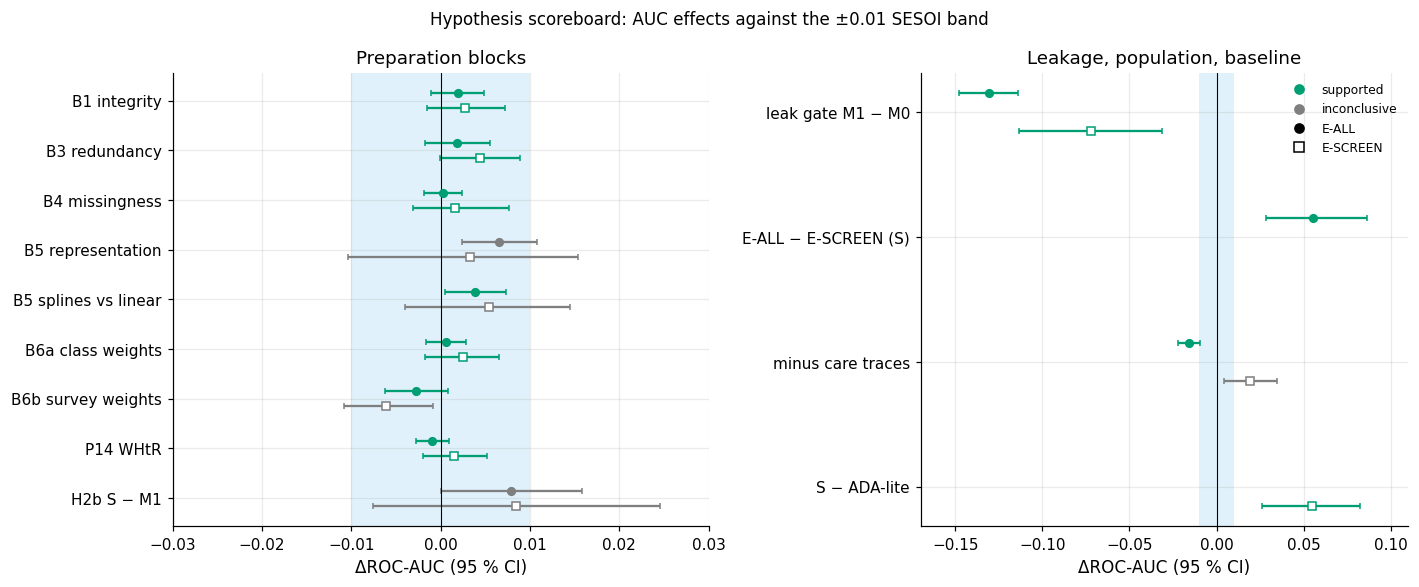

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
SEEN = set()
VCOL = {"supported": OI["green"], "equivalent": OI["blue"], "refuted": OI["vermillion"], "inconclusive": OI["grey"], "mixed": OI["purple"]}
LEFT = [("B1", "(a) AUC", "B1 integrity"), ("B3", "(a) AUC", "B3 redundancy"), ("B4", "(a) AUC", "B4 missingness"),
        ("B5", "(b) AUC block", "B5 representation"), ("B5", "(c) AUC splines", "B5 splines vs linear"),
        ("B6a", "(a) AUC", "B6a class weights"), ("B6b", "(a) unweighted AUC", "B6b survey weights"),
        ("P14", "(a) AUC", "P14 WHtR"), ("H2b", "(a) AUC", "H2b S − M1")]
RIGHT = [("B2", "(a) AUC M1-M0", "leak gate M1 − M0"), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)", "E-ALL − E-SCREEN (S)"),
         ("H2c", "(ii) minus care, E-ALL", "minus care traces"), ("H2c", "(iii) S - ADA-lite, E-SCREEN", "S − ADA-lite")]
for ax, spec, ttl, lim in ((axes[0], LEFT, "Preparation blocks", (-0.03, 0.03)), (axes[1], RIGHT, "Leakage, population, baseline", (-0.17, 0.11))):
    ylabels = []
    for i, (h, sub, lab) in enumerate(spec):
        g = det[(det["hyp_id"] == h) & (det["sub"].str.startswith(sub[:4])) & (det["metric"] == "roc_auc") & (det["tier"] == 1)]
        if h == "H2c" and sub.startswith("(ii)"):
            g = det[(det["hyp_id"] == "H2c") & det["sub"].str.startswith("(ii)")]
        for _, r in g.iterrows():
            off = -0.15 if r["pop"] in ("E-ALL", "E-ALL minus E-SCREEN") else 0.15
            col = VCOL.get(r["verdict"], OI["grey"])
            SEEN.add(r["verdict"])
            ax.errorbar(r["est"], i + off, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o" if off < 0 else "s",
                        color=col, mfc=col if off < 0 else "white", capsize=2, ms=5)
        ylabels.append(lab)
    ax.axvspan(-0.01, 0.01, color=OI["sky"], alpha=0.18, lw=0)
    ax.axvline(0, color="k", lw=0.7)
    ax.set_yticks(range(len(spec)), ylabels)
    ax.invert_yaxis()
    ax.set(xlim=lim, title=ttl, xlabel="ΔROC-AUC (95 % CI)")
from matplotlib.lines import Line2D
hand = [Line2D([], [], marker="o", ls="", color=c, label=v) for v, c in VCOL.items() if v in SEEN]
hand += [Line2D([], [], marker="o", ls="", color="k", label="E-ALL"), Line2D([], [], marker="s", ls="", color="k", mfc="white", label="E-SCREEN")]
axes[1].legend(handles=hand, fontsize=8, loc="upper right")
fig.suptitle("Hypothesis scoreboard: AUC effects against the ±0.01 SESOI band", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S10_scoreboard_forest", caption="F10-1. Paired ΔROC-AUC of the locked AUC sub-claims (Tier 1; filled = E-ALL, corrected t or "
              "bootstrap, the wider; hollow = E-SCREEN, bootstrap) with 95 % CIs, coloured by the sub-claim verdict under its locked rule; "
              "blue band = SESOI ±0.01. For equivalence claims 'supported' means the CI lies inside the band. Left: preparation blocks "
              "(leave-one-block-out) and the minimal-vs-systematic contrast; right: leakage gate, evaluation population, care traces and baseline.")
plt.show()

**So what.** One picture of the whole experiment: every preparation block sits inside or at the edge of
the ±0.01 band, while removing leakage (−0.13) and changing the evaluation population (+0.055) move AUC
by 5–13 times the SESOI. What the analyst *includes* and *whom the model is scored on* matter an order of
magnitude more than how carefully the admissible data are prepared.

## 3 Post-lock notes
**Why.** After the lock, the hypothesis file is only appended to by its owner; interpretations made later
must be visible as such. Three entries are recorded in the §10 decision register (not in the locked file):
the operational reading of H3, the source of the P14 verdict and the verdict of H1b.

In [6]:
POSTLOCK = [
    dict(item="H3 reading", note=("'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall "
                                  "(coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label "
                                  f"misses most – is secondary: {lm['row_wise_min']}."),
         consequence=f"H3 {lm['verdict']} under the column-wise reading; the row-wise pattern is reported as a descriptive finding"),
    dict(item="P14 verdict", note=f"§7 entered P14 as '{S7V['P14']['verdict']}' with part (b) deferred; §8 combined (a) and (b)",
         consequence=f"scoreboard uses the §8 combined verdict: {get('S8:verdicts.P14')}"),
    dict(item="H1b verdict", note="§4 reported crude and standardised differences but no verdict line",
         consequence=f"locked rule applied here: standardised {h1b_std:+.2f} pp [{h1b_lo:+.2f}, {h1b_hi:+.2f}] < +2 pp and below crude -> {h1b_v}"),
]
print(pd.DataFrame(POSTLOCK).to_string(index=False))

       item                                                                                                                                                                                                                                                                                                                           note                                                                                              consequence
 H3 reading 'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall (coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label misses most – is secondary: {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}. H3 inconclusive under the column-wise reading; the row-wise pattern is reported as a descriptive finding
P14 verdict                                                                                                                     

**So what.** None of the three notes changes a locked statement or a stored estimate; they make explicit
how two ambiguous or deferred items were resolved, so a reader can disagree with the reading without
having to reverse-engineer it.

## 4 Improvements and deteriorations
**Why.** The assignment asks for both directions to be explained. A deterioration can be the correct
outcome (removing leakage) and an improvement can be an artefact (a better balanced accuracy at 0.5 from
class weights). Each row gives the mechanism, the test that identifies it and the verdict.

In [7]:
lg = M["S7"]["leak_gate"]
hl = M["S7"]["headline"]
tm = M["S7"]["tree_m0"]
rw = pd.DataFrame(get("S8:reweighing.eod")).set_index(["arm", "group"])
blk = rw.loc[("S+RW(race)", "NH Black")]
asn = rw.loc[("S+RW(race)", "NH Asian")]
b6 = prim[prim["hyp_id"] == "B6a"].set_index("sub")
b5 = prim[prim["hyp_id"] == "B5"].set_index("sub")
ada = M["S7"]["ada_lr_minus_points"]["E-SCREEN"]
b6b_s = det[(det["hyp_id"] == "B6b") & (det["pop"] == "E-SCREEN")].iloc[0]


def ci3(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


IMPDET = pd.DataFrame([
    dict(change="Availability rule (M0 → M1)", direction="deterioration (correct)", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} / {ci3(lg['T1_E-SCREEN']['est'], lg['T1_E-SCREEN']['lo'], lg['T1_E-SCREEN']['hi'])}",
         mechanism="treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed",
         test=f"tree root on M0 = {M['S7']['tree_roots']['M0']['variable']} (leak role); M1/S root {M['S7']['tree_roots']['S']['variable']}; §9 leak hunt not triggered",
         verdict=f"H2a {S7V['H2a']['verdict']}, B2 {S7V['B2']['verdict']}, B2t {S7V['B2t']['verdict']}"),
    dict(change="Naive median imputation (M0 tree)", direction="deterioration on screening", metric="tree AUC E-SCREEN M0 vs M1",
         effect=f"{tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         mechanism=f"DID040 (age at diagnosis) {tm['did040_missing_share']:.0%} missing, filled with the median {tm['did040_fill']:.0f}: the split separates 'diagnosed' from 'imputed'",
         test="depth-3 tree on the M0 frame; level-2 split on DID040", verdict="descriptive (B2t probe)"),
    dict(change="Balanced class weights (B6a)", direction="deterioration (calibration) + artefactual gain", metric="ΔBrier / Δbalanced accuracy at 0.5",
         effect=f"{ci3(b6.loc['(b) Brier', 'est'], b6.loc['(b) Brier', 'lo'], b6.loc['(b) Brier', 'hi'])} / {ci3(b6.loc['(c) balanced accuracy at 0.5', 'est'], b6.loc['(c) balanced accuracy at 0.5', 'lo'], b6.loc['(c) balanced accuracy at 0.5', 'hi'])}",
         mechanism="re-weighting shifts every probability upward; ranking unchanged (ΔAUC "
                   f"{b6.loc['(a) AUC', 'est']:+.4f}); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold",
         test="leave-one-block-out, paired CV", verdict=f"B6a {S7V['B6a']['verdict']}; H2b(b) refuted"),
    dict(change="Systematic preparation without class weights (S−B6a vs M1)", direction="small improvement", metric="ΔAUC / ΔBrier E-ALL",
         effect=f"{ci3(pp_.loc[('E-ALL', 'roc_auc'), 'diff'], pp_.loc[('E-ALL', 'roc_auc'), 'lo'], pp_.loc[('E-ALL', 'roc_auc'), 'hi'])} / "
                f"{ci3(pp_.loc[('E-ALL', 'brier'), 'diff'], pp_.loc[('E-ALL', 'brier'), 'lo'], pp_.loc[('E-ALL', 'brier'), 'hi'], 4)}",
         mechanism="splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",
         test="paired bootstrap, exploratory (not locked)", verdict="below SESOI; not a verdict"),
    dict(change="Representation block (B5: Yeo-Johnson, scaling, splines)", direction="improvement (calibration)", metric="Δ|calibration slope − 1| E-ALL",
         effect=ci3(b5.loc['(a) |cal slope - 1|', 'est'], b5.loc['(a) |cal slope - 1|', 'lo'], b5.loc['(a) |cal slope - 1|', 'hi']),
         mechanism="mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test",
         test=f"LR χ²({M['S7']['lr_test_splines']['1']['df']}) = {M['S7']['lr_test_splines']['1']['chi2']:.1f}", verdict=f"B5 {S7V['B5']['verdict']}"),
    dict(change="Removing care traces (T1-minus-care vs S)", direction="deterioration on E-ALL, improvement on E-SCREEN", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(hl['minus_care_eall']['est'], hl['minus_care_eall']['lo'], hl['minus_care_eall']['hi'])} / {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         mechanism="hypertension-history items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",
         test="pre-registered ablation H2c(ii)", verdict="E-ALL supported; E-SCREEN 'unchanged' not supported (opposite sign)"),
    dict(change="ADA-lite items refitted by logistic regression (vs points)", direction="deterioration on E-SCREEN", metric="ΔAUC E-SCREEN",
         effect=ci3(ada['est'], ada['lo'], ada['hi']),
         mechanism="the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",
         test="paired bootstrap", verdict="descriptive"),
    dict(change="Survey-weighted fit (B6b)", direction="small deterioration", metric="ΔAUC E-ALL / E-SCREEN (unweighted metric)",
         effect=f"{ci3(prim[prim['hyp_id'] == 'B6b'].iloc[0]['est'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['lo'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['hi'])} / "
                f"{ci3(b6b_s['est'], b6b_s['lo'], b6b_s['hi'])}",
         mechanism="weights re-target the population and cut the effective n (Kish deff ≈ 1.5)", test="non-inferiority at −0.01",
         verdict=f"B6b {S7V['B6b']['verdict']}"),
    dict(change="Race reweighing (fairness mitigation)", direction="deterioration (NH Black gap widens)", metric="ΔEOD NH Black / NH Asian",
         effect=f"{ci3(blk['d_eod'], blk['d_eod_lo'], blk['d_eod_hi'])} / {ci3(asn['d_eod'], asn['d_eod_lo'], asn['d_eod_hi'])}",
         mechanism=f"race weights are near 1 (range {get('S8:reweighing.weight_range.race')[0]:.2f}–{get('S8:reweighing.weight_range.race')[1]:.2f}); "
                   "rebalancing prevalence moves the shared threshold away from the Black positives",
         test="paired bootstrap of EOD change", verdict="not adopted"),
])
print(IMPDET[["change", "direction", "effect", "verdict"]].to_string(index=False))
IMPDET.to_csv(OUT / "improvements_deteriorations.csv", index=False)

                                                    change                                       direction                                               effect                                                             verdict
                               Availability rule (M0 → M1)                         deterioration (correct)    -0.131 [-0.148, -0.114] / -0.072 [-0.113, -0.031]                          H2a supported, B2 supported, B2t supported
                         Naive median imputation (M0 tree)                      deterioration on screening                                       0.633 vs 0.701                                             descriptive (B2t probe)
                              Balanced class weights (B6a)  deterioration (calibration) + artefactual gain    +0.076 [+0.068, +0.084] / +0.145 [+0.123, +0.166]                                       B6a supported; H2b(b) refuted
Systematic preparation without class weights (S−B6a vs M1)                              

**So what.** The biggest change in the project is a *deterioration that is correct*: the availability
rule costs 0.13 AUC because that AUC was leakage – the naive tree's first split is a treatment question and
its second an imputation constant. The biggest *improvement* (balanced accuracy +0.14) is an artefact of
class weights that worsens the Brier score by 0.076; without class weights, systematic preparation improves
AUC by 0.007 and calibration slightly. Two deteriorations teach something about the data: dropping care
traces lowers whole-sample AUC but raises screening AUC, and refitting ADA items on our label lowers
screening AUC – both say the label rewards *recognising the diagnosed*. Race reweighing widens the NH Black
gap, which is why it was not adopted.

## 5 What the ML evidence says about the data
**Why.** The project's novelty is to use simple models as instruments that measure properties of the data.
Each row names the data property, the ML probe, the reading, the number and the evidence grade.

In [8]:
s3 = M["S3"]["blanket_recode"]
mask = M["S5"]["masking"]
cal = pd.DataFrame(get("S8:calibration.table")).set_index("group")
eod = pd.DataFrame(get("S8:eod_eall_t1")).set_index("group")
perm9 = M["S9"]["permutation"]
gdec = M["S8"]["gap_decomposition"]
flips = pd.DataFrame(get("S4:simpson.flips"))
n_med_flip = int((flips["role"] == "mediator").sum())
mnar = M["S9"]["mnar"]
dp = pd.DataFrame(mnar["delta_prevalence"]).set_index("odds_ratio")
WHAT = pd.DataFrame([
    dict(property="Skip-logic leakage", probe="leak gate M0 → M1; depth-3 tree root",
         reading="the naive model's high AUC is a questionnaire-design artefact",
         number=f"AUC {hl['auc_M0_eall_T1']:.3f} → {hl['auc_M1_eall_T1']:.3f}; ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])}; root {M['S7']['tree_roots']['M0']['variable']}",
         grade="E2"),
    dict(property="Imputation artefact", probe="M0 tree level-2 split",
         reading="a tree learns an imputation constant as if it were biology",
         number=f"DID040 {tm['did040_missing_share']:.0%} missing → {tm['did040_fill']:.0f}; tree E-SCREEN AUC {tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         grade="E1"),
    dict(property="Blanket sentinel cleaning", probe="per-variable vs blanket recode",
         reading="cleaning itself destroys information and labels",
         number=f"{s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']} HbA1c positives; {s3['l_comb_flips']}/{s3['l_comb_positives']} L_comb flips",
         grade="E1"),
    dict(property="Structural redundancy", probe="bootstrap SD of the BMI coefficient",
         reading="redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it",
         number=f"SD ratio unscaled {cs['ratio_cumulative']['ratio']:.2f}, inside scaled L2 {cs['ratio_B3']['ratio']:.2f}; ΔAUC B3 "
                f"{prim[(prim['hyp_id'] == 'B3') & (prim['sub'] == '(a) AUC')].iloc[0]['est']:+.4f}",
         grade="E3"),
    dict(property="Spectrum / label composition", probe="same predictions scored on E-ALL and E-SCREEN",
         reading="whole-sample AUC measures recognition of known diabetes",
         number=f"S {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
         grade="E2"),
    dict(property="Care traces", probe="T1-minus-care ablation on both populations",
         reading="contact-with-care items help recognition and hinder screening",
         number=f"E-ALL {hl['minus_care_eall']['est']:+.3f}; E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         grade="E3"),
    dict(property="Label is a measurement", probe="3 × 3 label matrix; treatment masking",
         reading="each label misses different people; no label lets these features find the undiagnosed",
         number=f"masking {mask['below_6_5']}/{mask['self_reported']} ({mask['below_6_5_share']:.1%}); recall Undiagnosed "
                f"{lm['recall']['Undiagnosed']['L_self']:.2f}/{lm['recall']['Undiagnosed']['L_A1c']:.2f}/{lm['recall']['Undiagnosed']['L_comb']:.2f}",
         grade="E3"),
    dict(property="Diagnosis gap by access", probe="model TPR diagnosed vs undiagnosed; group decomposition",
         reading="the model inherits who has been diagnosed",
         number=f"TPR diagnosed {gdec['tpr_diagnosed']:.2f} vs undiagnosed {gdec['tpr_undiagnosed']:.2f}; r(group TPR, care-trace share) {gdec['r_tpr_care_trace']:.2f}",
         grade="E3"),
    dict(property="BMI measurement bias", probe="single-feature AUC WHtR vs BMI; Asian TPR gap",
         reading="BMI under-measures adiposity in Asian adults; the full model only partly compensates",
         number=f"Asian gain {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White {get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}; "
                f"EOD Asian {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]",
         grade="E3 (Asian cells exploratory)"),
    dict(property="Calibration across groups", probe="observed : expected by race",
         reading="a race-blind model is calibrated on average, not within race",
         number="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         grade="E3"),
    dict(property="Procedure credibility", probe="label permutation; positive control",
         reading="no procedural leakage; weak real signal is detectable (does not exclude feature leakage)",
         number=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}; synthetic AUC-0.60 feature detected "
                f"({sum(r['detected'] for r in M['S9']['positive_control']['rows'])}/{len(M['S9']['positive_control']['rows'])})",
         grade="E1"),
    dict(property="Missing HbA1c", probe="IPW and delta-adjusted (MNAR) prevalence; S − M1 under MNAR",
         reading="missingness is not ignorable in principle but barely moves prevalence or the comparison",
         number=f"prevalence {dp.loc[1.0, 'prevalence']:.1%} (MAR) to {dp.iloc[-1]['prevalence']:.1%} at odds ratio {dp.index[-1]:.0f}; Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         grade="E3"),
])
print(WHAT.to_string(index=False))
WHAT.to_csv(OUT / "what_ml_says.csv", index=False)

                    property                                                       probe                                                                                  reading                                                                      number                        grade
          Skip-logic leakage                        leak gate M0 → M1; depth-3 tree root                            the naive model's high AUC is a questionnaire-design artefact                AUC 0.961 → 0.828; ΔAUC -0.131 [-0.148, -0.114]; root DIQ070                           E2
         Imputation artefact                                       M0 tree level-2 split                               a tree learns an imputation constant as if it were biology                   DID040 86% missing → 50; tree E-SCREEN AUC 0.633 vs 0.701                           E1
   Blanket sentinel cleaning                              per-variable vs blanket recode                                          cleaning itself destr

**So what.** Read top to bottom, the table is the project's argument: the data carry their *collection
process* inside them – skip patterns, imputation constants, sentinel codes, who has been diagnosed, who
answered, which body-size measure was taken – and an unexamined model learns that process instead of
diabetes. The probes that cost nothing in modelling sophistication (a depth-3 tree, an ablation, scoring the
same predictions on a second population) expose more about the data than any gain in AUC would.

## 6 Headline findings
**Why.** The video can carry three findings. Each must be backed by at least two independent lines of
evidence; one of them is chosen as the single headline non-obvious finding.

In [9]:
pc = pd.DataFrame(M["S9"]["positive_control"]["rows"])
HO = M["S9"].get("holdout", {})
HO_OK = "metrics" in HO
if HO_OK:
    HOM = pd.DataFrame(HO["metrics"]).set_index(["arm", "tier", "pop"])
    HOP = pd.DataFrame(HO["pairs"]).set_index(["comparison", "pop"])
print(f"hold-out available: {HO_OK}" + ("" if HO_OK else f" ({HO.get('status', 'missing')})"))
F = {
    "F1 Leakage and naive cleaning": [
        f"leak gate ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} (E-SCREEN {lg['T1_E-SCREEN']['est']:+.3f})",
        f"M0 tree splits on {M['S7']['tree_roots']['M0']['variable']} then on DID040 = median {tm['did040_fill']:.0f} ({tm['did040_missing_share']:.0%} missing); "
        f"tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} < M1 {tm['escreen_auc']['M1']:.3f}",
        f"blanket recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']} vs {s3['l_comb_flips']} label flips (HbA1c-only vs frozen L_comb)",
        f"§9 leak hunt on admissible arms: not triggered (max single-feature AUC {M['S9']['leak_hunt']['strongest_admissible']['auc']:.3f})"]
    + ([f"hold-out M1 − M0 {ci3(HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'est'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'lo'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'hi'])}"] if HO_OK else []),
    "F2 Fallacies and measurement of performance": [
        f"insurance gap {ins['crude']:+.1f} → {ins['std']:+.1f} pp after age standardisation (attenuation)",
        f"Asian − White {get('S4:standardisation.asian_white.crude'):+.1f} → {get('S4:standardisation.asian_white.std'):+.1f} pp, both CIs include 0",
        f"BMI is a mediator in the DAG; {n_med_flip} of {len(flips)} Simpson sign flips come from mediator stratifiers",
        f"spectrum gap E-ALL − E-SCREEN {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
        f"care-trace reversal: E-ALL {hl['minus_care_eall']['est']:+.3f}, E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}"],
    "F3 Label and measurement bias": [
        f"treatment masking {mask['below_6_5']}/{mask['self_reported']} = {mask['below_6_5_share']:.1%} ({mask['below_6_5_on_med']} on medication)",
        f"undiagnosed risk difference uninsured − insured {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
        f"3 × 3 matrix: H3 {lm['verdict']}; Undiagnosed is the lowest-recall stratum for every training label",
        f"NH Asian TPR gap {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}], race permutation p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
        f"WHtR − BMI single-feature gain difference Asian − White {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]",
        "calibration O:E by race " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"])],
}
for k, v in F.items():
    print(k)
    for line in v:
        print("   -", line)

# headline: whole-sample AUC measures recognition of known diabetes, not screening
HEAD_LINES = [
    ("pre-registered spectrum gap (H2c-i, supported)", f"{ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}"),
    ("care-trace ablation changes sign between populations (H2c-ii)", f"E-ALL {hl['minus_care_eall']['est']:+.3f} vs E-SCREEN {hl['minus_care_escreen']['est']:+.3f}"),
    ("ADA items refitted on L_comb lose screening AUC", f"{ada['est']:+.3f} [{ada['lo']:+.3f}, {ada['hi']:+.3f}]"),
    ("§8 TPR: diagnosed vs undiagnosed positives at the same threshold", f"{gdec['tpr_diagnosed']:.2f} vs {gdec['tpr_undiagnosed']:.2f}"),
    ("§8 3 × 3 matrix: Undiagnosed column lowest under every label", str(lm["row_wise_min"])),
    ("leakage also is recognition: the leak gate is smaller on E-SCREEN", f"{lg['T1_E-ALL']['est']:+.3f} vs {lg['T1_E-SCREEN']['est']:+.3f}"),
]
if HO_OK:
    s_all, s_scr = HOM.loc[("S", 1, "E-ALL"), "roc_auc"], HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"]
    HEAD_LINES.append(("one-shot hold-out: same gap for arm S", f"E-ALL {s_all:.3f} vs E-SCREEN {s_scr:.3f} (gap {s_all - s_scr:+.3f})"))
print("\nHEADLINE – whole-sample AUC measures recognition of known diabetes, not screening; independent evidence lines:")
for a, b in HEAD_LINES:
    print(f"   - {a}: {b}")
S10["headline"] = dict(finding="Whole-sample AUC measures recognition of known diabetes, not screening",
                       n_evidence_lines=len(HEAD_LINES), lines=[f"{a}: {b}" for a, b in HEAD_LINES])
S10["findings"] = F

hold-out available: False (not evaluated: exp-freeze tag missing)
F1 Leakage and naive cleaning
   - leak gate ΔAUC -0.131 [-0.148, -0.114] (E-SCREEN -0.072)
   - M0 tree splits on DIQ070 then on DID040 = median 50 (86% missing); tree E-SCREEN AUC M0 0.633 < M1 0.701
   - blanket recode destroys 1,496 valid cells; 29 vs 6 label flips (HbA1c-only vs frozen L_comb)
   - §9 leak hunt on admissible arms: not triggered (max single-feature AUC 0.706)
F2 Fallacies and measurement of performance
   - insurance gap +5.3 → +0.7 pp after age standardisation (attenuation)
   - Asian − White -0.8 → +2.1 pp, both CIs include 0
   - BMI is a mediator in the DAG; 4 of 6 Simpson sign flips come from mediator stratifiers
   - spectrum gap E-ALL − E-SCREEN +0.055 [+0.028, +0.086]
   - care-trace reversal: E-ALL -0.016, E-SCREEN +0.019 [+0.004, +0.034]
F3 Label and measurement bias
   - treatment masking 250/819 = 30.5% (165 on medication)
   - undiagnosed risk difference uninsured − insured +23.2 pp [6.2

**So what – choice of the headline.** The single non-obvious finding is **"a whole-sample AUC measures
recognition of known diabetes, not screening"**. It is chosen over the leakage gate (large but expected once
the availability rule is stated) and over the Asian TPR gap (important but exploratory, 40 positives)
because it is (i) **non-obvious** – the standard practice of reporting one AUC on the whole sample hides it,
and it arises from label composition (84 % of positives already diagnosed), not from the model; (ii)
**pre-registered** (H2c, `prior_exposure = none`); (iii) carried by **six independent lines** from three
sections (a population contrast, a feature ablation that flips sign, a baseline refit, group TPRs, the label
matrix and the leak gate), plus the hold-out once evaluated; and (iv) **actionable**: report E-SCREEN next to
E-ALL and keep care traces out of screening models. The leakage and naive-cleaning results (F1) and the
label and measurement biases (F3) are the other two video findings.

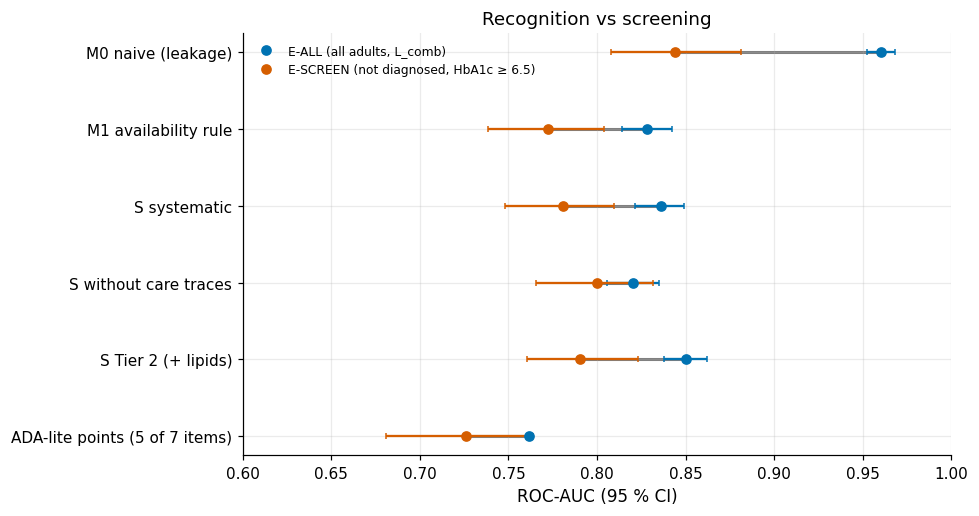

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
am = pd.DataFrame(M["S7"]["arm_metrics"]).set_index(["arm", "tier", "model"])
bl = M["S7"]["baselines"]
ARMS_FIG = [("M0", 1, "M0 naive (leakage)"), ("M1", 1, "M1 availability rule"), ("S", 1, "S systematic"),
            ("T1-minus-care", 1, "S without care traces"), ("S", 2, "S Tier 2 (+ lipids)")]
for i, (a, t, lab) in enumerate(ARMS_FIG):
    r = am.loc[(a, t, "lr")]
    ax.plot([r["escr_auc"], r["eall_auc"]], [i, i], color=OI["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall_auc"], i, xerr=[[r["eall_auc"] - r["eall_auc_lo"]], [r["eall_auc_hi"] - r["eall_auc"]]], fmt="o", color=OI["blue"], capsize=2, zorder=2)
    ax.errorbar(r["escr_auc"], i, xerr=[[r["escr_auc"] - r["escr_auc_lo"]], [r["escr_auc_hi"] - r["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2, zorder=2)
    if HO_OK and (a, t, "E-ALL") in HOM.index:
        ax.plot(HOM.loc[(a, t, "E-ALL"), "roc_auc"], i - 0.25, "^", color=OI["blue"], mfc="white", ms=6)
        ax.plot(HOM.loc[(a, t, "E-SCREEN"), "roc_auc"], i - 0.25, "^", color=OI["vermillion"], mfc="white", ms=6)
j = len(ARMS_FIG)
ada_p = bl["BL-ADAlite (points)"]
ax.errorbar(ada_p["escr_auc"], j, xerr=[[ada_p["escr_auc"] - ada_p["lo"]], [ada_p["hi"] - ada_p["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2)
ax.plot(ada_p["eall_auc"], j, "o", color=OI["blue"])
ax.plot([ada_p["escr_auc"], ada_p["eall_auc"]], [j, j], color=OI["grey"], lw=2, zorder=0)
ax.set_yticks(range(j + 1), [l for _, _, l in ARMS_FIG] + ["ADA-lite points (5 of 7 items)"])
ax.invert_yaxis()
leg = [Line2D([], [], marker="o", ls="", color=OI["blue"], label="E-ALL (all adults, L_comb)"),
       Line2D([], [], marker="o", ls="", color=OI["vermillion"], label="E-SCREEN (not diagnosed, HbA1c ≥ 6.5)")]
if HO_OK:
    leg.append(Line2D([], [], marker="^", ls="", color="k", mfc="white", label="one-shot hold-out"))
ax.legend(handles=leg, fontsize=8, loc="upper left")
ax.set(xlabel="ROC-AUC (95 % CI)", xlim=(0.6, 1.0), title="Recognition vs screening")
fig.tight_layout()
plots.savefig(fig, "S10_recognition_vs_screening", caption="F10-2. The same out-of-fold predictions scored on E-ALL (blue; all adults, 84 % of "
              "positives already diagnosed) and E-SCREEN (red; adults without a diagnosis, positive = HbA1c ≥ 6.5 %), training part, 95 % "
              "bootstrap CIs; triangles = one-shot hold-out where available. Every arm loses AUC on the screening population; the arm without "
              "care-trace items is the only one that ranks higher on E-SCREEN than arm S.")
plt.show()

**So what.** The grey bars are the price of moving from "recognise the diagnosed" to "find the
undiagnosed": about 0.12 for the leaky M0, about 0.055 for the admissible arms, and only 0.02 for the arm
without care traces – which is the best screening model of all although it is the worst on E-ALL.

## 7 Claims ledger
**Why.** Every statement that will appear in the abstract or the video becomes a row of
`governance/claims.csv` with its grade, evidence, CI, robustness, external reference, scope, falsifier and
video segment. Rules enforced in code: at most 25 words; the verb follows the grade (E1 *confirms that*, E2
*shows that*, E3 *is consistent with the view that*, E4 *suggests that*); no causal verbs; a **headline**
claim with fewer than two independent evidence lines is downgraded by one grade automatically.

In [11]:
LADDER = {"E1": "confirms that", "E2": "shows that", "E3": "is consistent with the view that", "E4": "suggests that"}
CAUSAL = re.compile(r"\b(caus\w*|drive[sn]?|driven|leads? to|results? in|due to|because|impact\w*|effect of|prevent\w*)\b", re.I)
VSEG = {"V1": "0:00-1:30 scope and design", "V2": "1:30-2:15 cost of naive cleaning", "V3": "2:15-3:30 leakage gate",
        "V4": "3:30-4:30 redundancy and skew", "V5": "4:30-6:00 fallacies", "V6": "6:00-8:30 label and measurement bias",
        "V7": "8:30-10:15 models and evaluation", "V8": "10:15-11:20 what ML says about the data"}
sm = M["S9"]["summary"]["table"]
sm_e = {r["check"]: r for r in sm if r["pop"] == "E-ALL"}
ROB_H2B = (f"10 seeds {sm_e['10 CV seeds']['verdicts']}; 16 specs {sm_e['16 sensitivity specs']['verdicts']}; "
           f"60-spec curve {sm_e['60-spec curve']['verdicts']}; PSU-grouped CV and IPW inconclusive")
ROB_LEAK = (f"own-C tuning gives the same gate {M['S9']['sensitivity']['leak_gate_own_C']['E-ALL']['est']:+.3f}; permutation null "
            f"{perm9['M1']['null_mean']:.3f}; leak hunt not triggered")
ROB_NONE = "not varied in §9 (single specification)"
db = M["S4"]["db516"]
v2 = pd.DataFrame(M["S9"]["external"]["v2"]).set_index("quantity")
v2d = v2.loc["definition effect C - B"]
EXT_DB = f"NCHS DB516: reproduced {db['total']:.2f}/{db['diagnosed']:.2f}/{db['undiagnosed']:.2f} % vs published 15.8/11.3/4.5"
sw = lambda r: f"{r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]"
und = get("S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1)")
pe = lambda h: HYP.loc[h, "prior"]
eod_b = rw.loc[("S+RW(race)", "NH Black")]
whtr_a = get("S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc")
whtr_w = get("S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc")
max_lab_diff = float(h3c["est"].abs().max())
hx = h3c.loc[h3c["est"].abs().idxmax()]
fx = flips[flips["role"] == "mediator"].iloc[0]
oe_lo = min(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
oe_hi = max(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])

CL = [
    dict(cid="C01", vs="V3", head=True, grade="E2", type="leakage", subj="The leak gate",
         prop=f"removing skip-logic and treatment items lowers E-ALL AUC by {-lg['T1_E-ALL']['est']:.2f}, and the excess was leakage",
         ev=["§7 paired CV leak gate (H2a/B2)", "§7 depth-3 tree root on a treatment item (B2t)", "§9 leak hunt on admissible arms", "§9 permutation null"]
            + (["§9 one-shot hold-out M1 − M0"] if HO_OK else []),
         eff=f"ΔAUC M1 − M0 E-ALL {sw(lg['T1_E-ALL'])}; E-SCREEN {sw(lg['T1_E-SCREEN'])}", prereg=pe("H2a"), rob=ROB_LEAK, ext="none",
         scope="training part, Tier 1, E-ALL", fals="CI of M1 − M0 reaching above −0.05", hyp="H2a;B2;B2t"),
    dict(cid="C02", vs="V3", head=False, grade="E1", type="data_artefact", subj="The naive tree",
         prop=f"median imputation turns age at diagnosis ({tm['did040_missing_share']:.0%} missing) into a constant {tm['did040_fill']:.0f} that the tree splits on",
         ev=["§7 tree structure of M0"], eff=f"fill {tm['did040_fill']:.0f}; tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} vs M1 {tm['escreen_auc']['M1']:.3f} (descriptive)",
         prereg="none (tree probe B2t)", rob=ROB_NONE, ext="none", scope="M0 frame, training part", fals="M0 tree without a DID040 split", hyp="B2t"),
    dict(cid="C03", vs="V2", head=False, grade="E1", type="cleaning_cost", subj="The sentinel audit",
         prop=f"a blanket 7/9/77/99 recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells and {s3['a1c_positives_lost']} of {s3['a1c_positives']} HbA1c-positive labels",
         ev=["§2 per-variable vs blanket recode counts", "§6 label rebuilt from naive data (965 vs 971 positives)"],
         eff=f"{s3['valid_cells_destroyed_cohort']:,} cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']}; L_comb flips {s3['l_comb_flips']}/{s3['l_comb_positives']}",
         prereg="analysis_seen", rob="deterministic count", ext="NHANES codebooks (sentinels only on questionnaire items)", scope="cohort 5,730",
         fals="a recount giving a different number", hyp="B1"),
    dict(cid="C04", vs="V2", head=False, grade="E2", type="fidelity", subj="Leave-one-block-out ablation",
         prop=f"repairing XPT zeros and sentinels changes E-ALL AUC by only {prim[(prim['hyp_id'] == 'B1')].iloc[0]['est']:+.3f}: justified by fidelity, not performance",
         ev=["§7 paired CV B1", "§7 E-SCREEN and Tier 2 replicates"], eff=f"ΔAUC {sw(prim[prim['hyp_id'] == 'B1'].iloc[0])}",
         prereg=pe("B1"), rob="same verdict on E-SCREEN and Tier 2", ext="none", scope="training part", fals="CI wholly beyond ±0.01", hyp="B1"),
    dict(cid="C05", vs="V7", head=True, grade="E3", type="minimal_vs_systematic", subj="The M1-versus-S contrast",
         prop=f"systematic preparation changes AUC by under {h2b.loc['(a) AUC', 'hi']:.3f}; equivalence stays unestablished (MDD {h2b.loc['(a) AUC', 'mdd']:.3f})",
         ev=["§7 paired CV H2b(a)", "§9 ten seeds", "§9 16-spec table", "§9 60-spec curve", "§9 PSU-grouped CV"] + (["§9 one-shot hold-out S − M1"] if HO_OK else []),
         eff=f"ΔAUC {sw(h2b.loc['(a) AUC'])}; Brier {h2b.loc['(b) Brier', 'est']:+.3f} (refuted, class weights); pure preparation ΔAUC {pp_.loc[('E-ALL', 'roc_auc'), 'diff']:+.3f}",
         prereg=pe("H2b"), rob=ROB_H2B, ext="none", scope="training part, E-ALL, Tier 1", fals="CI of S − M1 wholly beyond ±0.01", hyp="H2b"),
    dict(cid="C06", vs="V7", head=False, grade="E2", type="deterioration", subj="Paired cross-validation",
         prop=f"balanced class weights worsen the Brier score by {b6.loc['(b) Brier', 'est']:.3f} at unchanged AUC; without them preparation costs no calibration",
         ev=["§7 paired CV B6a(b)", "§7 pure-preparation contrast S−B6a vs M1"], eff=f"ΔBrier {sw(b6.loc['(b) Brier'])}; without weights {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         prereg=pe("B6a"), rob="E-SCREEN and Tier 2 same direction", ext="none", scope="training part", fals="Brier CI including 0", hyp="B6a;H2b"),
    dict(cid="C07", vs="V7", head=True, grade="E2", type="spectrum", subj="Scoring arm S on E-SCREEN",
         prop=f"whole-sample AUC overstates screening discrimination by {hl['eall_minus_escreen_S_T1']['est']:.3f}; most positives were already diagnosed",
         ev=[a for a, _ in HEAD_LINES], eff=f"AUC {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {sw(hl['eall_minus_escreen_S_T1'])}",
         prereg=pe("H2c"), rob="all admissible arms lose AUC on E-SCREEN" + ("; hold-out shows the same gap" if HO_OK else ""), ext="none",
         scope="US adults 2021-23; screening = not yet diagnosed", fals="gap CI including 0 in a new sample", hyp="H2c"),
    dict(cid="C08", vs="V7", head=True, grade="E3", type="care_traces", subj="The care-trace ablation",
         prop=f"removing hypertension-history items lowers E-ALL AUC by {-hl['minus_care_eall']['est']:.3f} yet raises E-SCREEN AUC by {hl['minus_care_escreen']['est']:.3f}",
         ev=["§7 paired ablation H2c(ii) on E-ALL", "§7 same ablation on E-SCREEN", "§9 leak hunt T1-minus-care contrast"]
            + (["§9 one-shot hold-out T1-minus-care − S"] if HO_OK else []),
         eff=f"E-ALL {sw(hl['minus_care_eall'])}; E-SCREEN {sw(hl['minus_care_escreen'])}", prereg=pe("H2c"),
         rob="E-SCREEN CI excludes 0 but reaches below the SESOI", ext="none", scope="training part, Tier 1", fals="E-SCREEN difference CI including 0", hyp="H2c"),
    dict(cid="C09", vs="V7", head=False, grade="E2", type="baseline", subj="The E-SCREEN baseline comparison",
         prop=f"arm S ranks undiagnosed cases better than the five-item ADA-lite points score, by {hl['S_minus_ADAlite_escreen']['est']:.3f} AUC",
         ev=["§7 paired bootstrap H2c(iii)"] + (["§9 one-shot hold-out S − ADA-lite"] if HO_OK else []),
         eff=f"ΔAUC {sw(hl['S_minus_ADAlite_escreen'])}", prereg=pe("H2c"), rob=ROB_NONE,
         ext="Bang 2009 ADA risk test (qualitative only; ADA-lite lacks 2 of 7 items)", scope="E-SCREEN, training part", fals="CI including 0", hyp="H2c"),
    dict(cid="C10", vs="V7", head=False, grade="E3", type="deterioration", subj="Refitting ADA-lite items on L_comb",
         prop=f"this diagnosis-dominated label lowers screening AUC by {-ada['est']:.3f} versus the points score",
         ev=["§7 paired bootstrap ADA-LR vs points"], eff=f"ΔAUC E-SCREEN {sw(ada)}", prereg="none (not locked)", rob=ROB_NONE,
         ext="none", scope="E-SCREEN, training part", fals="CI including 0", hyp=""),
    dict(cid="C11", vs="V5", head=False, grade="E2", type="fallacy", subj="Age standardisation",
         prop=f"the insured-minus-uninsured prevalence gap shrinks from {ins['crude']:+.1f} to {ins['std']:+.1f} pp: age confounding, not a reversal",
         ev=["§4 jackknife crude vs standardised difference", "§4 age-band differences"],
         eff=f"crude {ins['crude']:+.1f} [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> std {ins['std']:+.1f} [{ins['std_ci'][0]:+.1f}, {ins['std_ci'][1]:+.1f}] pp",
         prereg=pe("H1b"), rob="6-band and internal standards give std ≤ +0.7 pp", ext="US 2000 standard population", scope="US adults 2021-23, weighted",
         fals="standardised gap ≥ +2 pp with CI excluding 0", hyp="H1b"),
    dict(cid="C12", vs="V5", head=False, grade="E4", type="uncertainty", subj="Age standardisation",
         prop=f"the Asian-minus-White prevalence difference changes sign ({get('S4:standardisation.asian_white.crude'):+.1f} to {get('S4:standardisation.asian_white.std'):+.1f} pp), but both intervals include 0",
         ev=["§4 jackknife standardised difference"],
         eff=f"crude {get('S4:standardisation.asian_white.crude'):+.1f} [{get('S4:standardisation.asian_white.crude_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.crude_ci')[1]:+.1f}]; "
             f"std {get('S4:standardisation.asian_white.std'):+.1f} [{get('S4:standardisation.asian_white.std_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.std_ci')[1]:+.1f}] pp",
         prereg="analysis_seen", rob="direction same under 6-band and internal standards", ext="none", scope="NH Asian n = 315 (exploratory)",
         fals="a CI excluding 0", hyp=""),
    dict(cid="C13", vs="V5", head=False, grade="E3", type="dag", subj="The DAG-guided Simpson scan",
         prop=f"BMI is a mediator, not a confounder, of race differences ({n_med_flip}/{len(flips)} flips involve mediators)",
         ev=["§4 DAG adjustment sets", "§4 224-comparison Simpson scan"], eff=f"{len(flips)} flips in {M['S4']['simpson']['n_comparisons']} comparisons; e.g. {fx['exposure']} by {fx['stratifier']}: crude {fx['crude']:+.1f} [{fx['crude_low']:+.1f}, {fx['crude_high']:+.1f}] -> std {fx['std']:+.1f} [{fx['std_low']:+.1f}, {fx['std_high']:+.1f}] pp; P(sign differs) {flips['p_sign_differs'].min():.2f}-{flips['p_sign_differs'].max():.2f}",
         prereg="analysis_seen", rob=f"bootstrap flip probabilities ≤ {flips['p_sign_differs'].max():.2f} (exploratory)", ext="none", scope="structural assumption", fals="a DAG in which BMI precedes race-related exposure", hyp=""),
    dict(cid="C14", vs="V6", head=True, grade="E1", type="label_bias", subj="The label audit",
         prop=f"{mask['below_6_5']} of {mask['self_reported']} self-reported diabetics ({mask['below_6_5_share']:.1%}) have HbA1c below 6.5, so an HbA1c-only label calls them negative",
         ev=["§5 label cross-tabulation", "§5 medication split (165 treated)", "§8 3 × 3 matrix D-controlled column"],
         eff=f"{mask['below_6_5']}/{mask['self_reported']}; {mask['below_6_5_on_med']} on medication", prereg="analysis_seen", rob="deterministic count",
         ext="none", scope="cohort 5,730", fals="a recount giving a different number", hyp="H3"),
    dict(cid="C15", vs="V6", head=False, grade="E3", type="label_bias", subj="The risk-difference analysis",
         prop=f"uninsured adults with diabetes are more often undiagnosed, by {rd['rd_pp']:.1f} pp (weighted; uninsured share exploratory)",
         ev=["§5 jackknife risk difference", "§5 adjusted logit (age, sex, income)"], eff=f"RD {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
         prereg=pe("H1a"), rob="adjusted OR 2.2 [1.2, 4.2]", ext="none", scope="adults with diabetes, weighted; uninsured n = 49", fals="RD CI including 0", hyp="H1a"),
    dict(cid="C16", vs="V6", head=False, grade="E1", type="label_semantics", subj="The care-contact audit",
         prop=f"{und['n']} of {M['S5']['undiagnosed_meaning']['undiagnosed']} undiagnosed adults ({und['share']:.0%}) had a blood test within three years: a diagnosis gap, not only access",
         ev=["§5 DIQ180 among the undiagnosed", "§5 told borderline 24 %"], eff=f"{und['n']}/{M['S5']['undiagnosed_meaning']['undiagnosed']}; weighted {und['w_est']:.0%} [{und['kg_low']:.0%}, {und['kg_high']:.0%}]",
         prereg="analysis_seen", rob="deterministic count", ext="none", scope="undiagnosed, cohort", fals="a recount giving a different number", hyp=""),
    dict(cid="C17", vs="V6", head=True, grade="E3", type="label_matrix", subj="The label matrix",
         prop=f"every label finds undiagnosed cases worst; switching labels moves recall by at most {max_lab_diff:.2f}",
         ev=["§8 3 × 3 matrix contrasts (H3)", "§8 TPR diagnosed vs undiagnosed", "§7 E-SCREEN recall of arm S"],
         eff=f"recall Undiagnosed L_self {lm['recall']['Undiagnosed']['L_self']:.3f}, L_A1c {lm['recall']['Undiagnosed']['L_A1c']:.3f}, L_comb {lm['recall']['Undiagnosed']['L_comb']:.3f}; largest contrast {hx['est']:+.3f} [{hx['lo']:+.3f}, {hx['hi']:+.3f}]; H3 {lm['verdict']}",
         prereg=pe("H3"), rob=ROB_NONE, ext="none", scope="training part, Tier 1", fals="a label with Undiagnosed recall exceeding another stratum's", hyp="H3"),
    dict(cid="C18", vs="V6", head=False, grade="E4", type="fairness", subj="The group audit",
         prop=f"the model flags NH Asian adults with diabetes less often than White adults, TPR gap {eod.loc['NH Asian', 'eod']:+.2f}",
         ev=["§8 EOD with bootstrap CI and permutation null"], eff=f"EOD {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]; race p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
         prereg="none (audit)", rob="Tier 2 gap " + f"{pd.DataFrame(M['S8']['tier2_summary']['eod']).set_index('group').loc['NH Asian', 'eod']:+.3f}",
         ext="ADA advice to screen Asian Americans from BMI 23", scope="E-ALL, 40 Asian positives (exploratory)", fals="CI including 0 in a larger sample", hyp=""),
    dict(cid="C19", vs="V6", head=False, grade="E3", type="measurement", subj="Single-feature discrimination",
         prop=f"WHtR outranks BMI more for Asian ({whtr_a:+.3f}) than White adults ({whtr_w:+.3f}), not in the full model",
         ev=["§5 paired single-feature AUC with PSU bootstrap", "§8 model-level WHtR arm (P14)"],
         eff=f"gain difference {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]; model level {mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}]",
         prereg=pe("H4b"), rob="person and PSU bootstrap agree", ext="ADA advice to screen Asian Americans from BMI 23", scope="NH Asian 296 with WHtR (exploratory)",
         fals="gain difference CI including 0", hyp="H4b;P14"),
    dict(cid="C20", vs="V6", head=False, grade="E3", type="calibration", subj="Within-group calibration",
         prop="the race-blind model under-predicts for Black, Asian and Mexican American adults and over-predicts for White adults",
         ev=["§8 observed : expected by race with bootstrap CI"], eff="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f} [{cal.loc[g, 'oe_lo']:.2f}, {cal.loc[g, 'oe_hi']:.2f}]" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         prereg="none (audit)", rob=ROB_NONE, ext="none", scope="training part, S without class weights", fals="O:E CIs including 1", hyp=""),
    dict(cid="C21", vs="V7", head=False, grade="E3", type="mitigation", subj="The race-reweighing arm",
         prop=f"it leaves AUC and the Asian gap unchanged and widens the NH Black gap by {-eod_b['d_eod']:.3f}",
         ev=["§8 paired bootstrap of EOD change"], eff=f"ΔEOD NH Black {eod_b['d_eod']:+.3f} [{eod_b['d_eod_lo']:+.3f}, {eod_b['d_eod_hi']:+.3f}]",
         prereg="none (mitigation arm)", rob=ROB_NONE, ext="none", scope="E-ALL, training part", fals="ΔEOD CI including 0", hyp=""),
    dict(cid="C22", vs="V7", head=False, grade="E1", type="credibility", subj="The control analysis",
         prop=f"the evaluation returns AUC {perm9['S']['null_mean']:.2f} without signal and detects a weak synthetic feature",
         ev=["§9 100 label permutations", "§9 positive control"], eff=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}",
         prereg="none (control)", rob="both arms", ext="none", scope="procedure only, not feature leakage", fals="null mean outside [0.495, 0.505]", hyp=""),
    dict(cid="C23", vs="V1", head=False, grade="E2", type="external", subj="Replicating NCHS Data Brief 516",
         prop=f"our survey code reproduces published prevalence ({db['total']:.2f} vs 15.8 %) and our {v2.loc['A L_comb, cohort, WTPH2YR', 'est_pct']:.1f} % differs by label definition",
         ev=["§4 DB516 replication (27 estimates)", "§9 V2 decomposition sample vs definition"],
         eff=f"max |diff| {db['max_abs_diff_pp']:.3f} pp; definition effect {v2d['est_pct']:+.2f} [{v2d['ci_low']:+.2f}, {v2d['ci_high']:+.2f}] pp",
         prereg="analysis_seen", rob=f"{db['kg_matches_published_ci']}/{db['n_estimates']} published CIs matched", ext=EXT_DB, scope="US adults 2021-23",
         fals="replication difference > 0.1 pp", hyp=""),
    dict(cid="C24", vs="V8", head=False, grade="E3", type="missingness", subj="The missing-data analysis",
         prop=f"missing HbA1c barely shifts prevalence: {dp.loc[1.0, 'prevalence']:.1%} to {dp.iloc[-1]['prevalence']:.1%} even if non-responders' odds are {dp.index[-1]:.0f}-fold",
         ev=["§9 IPW reweighting", "§9 delta adjustment", "§5 Manski bounds"], eff=f"Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]; tipping delta to DB516 {mnar['tipping_delta_db516']:.2f}",
         prereg="none (sensitivity)", rob="S − M1 unchanged across deltas", ext=EXT_DB, scope="examined adults", fals="MNAR untestable: assumption, not test", hyp=""),
]
if HO_OK:
    nflag = int(HO.get("n_flag_2se", 0))
    hS = HOM.loc[("S", 1)]
    CL.append(dict(cid="C25", vs="V7", head=False, grade="E2" if nflag == 0 else "E3", type="holdout", subj="The one-shot hold-out",
                   prop=f"cross-validated AUCs carry over: arm S {hS.loc['E-ALL', 'roc_auc']:.3f} on E-ALL and {hS.loc['E-SCREEN', 'roc_auc']:.3f} on E-SCREEN",
                   ev=["§9 hold-out after exp-freeze", "§7 cross-validation"],
                   eff=f"E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}]; E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} "
                       f"[{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}]; {nflag} rows > 2 SE below CV",
                   prereg="none (one shot)", rob="evaluated once; SHA-256 of test IDs logged", ext="none", scope="20 % hold-out (1,146 adults)",
                   fals="hold-out AUC > 2 SE below CV", hyp="H2a;H2b;H2c"))

GRADES = ["E1", "E2", "E3", "E4"]
recs, PROBLEMS = [], []
for c in CL:
    g = c["grade"]
    n_lines = len(c["ev"])
    downgraded = c["head"] and n_lines < 2
    if downgraded:
        g = GRADES[min(GRADES.index(g) + 1, 3)]
    stmt = f"{c['subj']} {LADDER[g]} {c['prop']}."
    nw = len(stmt.split())
    if nw > 25:
        PROBLEMS.append((c["cid"], f"{nw} words", stmt))
    if CAUSAL.search(stmt):
        PROBLEMS.append((c["cid"], f"causal verb '{CAUSAL.search(stmt).group(0)}'", stmt))
    if g != "E1" and not (re.search(r"[\[(]", c["eff"]) or "descriptive" in c["eff"]):
        PROBLEMS.append((c["cid"], "non-E1 claim without CI", c["eff"]))
    recs.append(dict(claim_id=c["cid"], statement=stmt, type=c["type"], evidence_refs=" | ".join(c["ev"]), effect_ci=c["eff"], grade=g,
                     prereg=c["prereg"], robustness=c["rob"], external_ref=c["ext"], scope=c["scope"], falsifier=c["fals"],
                     video_seg=f"{c['vs']} {VSEG[c['vs']]}", headline=c["head"], n_evidence_lines=n_lines, downgraded=downgraded,
                     hyp_ids=c["hyp"], words=nw))
assert not PROBLEMS, " || ".join(map(str, PROBLEMS))
CLAIMS = pd.DataFrame(recs)
print(CLAIMS[["claim_id", "grade", "headline", "n_evidence_lines", "downgraded", "words", "statement"]].to_string(index=False))
print(f"\n{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; headline claims "
      f"{int(CLAIMS['headline'].sum())}, all with ≥ 2 evidence lines: {bool((CLAIMS.loc[CLAIMS['headline'], 'n_evidence_lines'] >= 2).all())}; "
      f"downgraded {int(CLAIMS['downgraded'].sum())}; max words {CLAIMS['words'].max()}")
CL_COLS = ["claim_id", "statement", "type", "evidence_refs", "effect_ci", "grade", "prereg", "robustness", "external_ref", "scope", "falsifier", "video_seg"]
CLAIMS.to_csv(OUT / "claims_full.csv", index=False)
if C.IS_FINAL:
    CLAIMS[CL_COLS].to_csv(C.GOVERNANCE_DIR / "claims.csv", index=False)
    print("wrote governance/claims.csv (schema of the process document §7.2)")
else:
    print("FAST run: governance/claims.csv not written (the committed ledger comes from the FINAL run)")

claim_id grade  headline  n_evidence_lines  downgraded  words                                                                                                                                                                      statement
     C01    E2      True                 4       False     20                                                         The leak gate shows that removing skip-logic and treatment items lowers E-ALL AUC by 0.13, and the excess was leakage.
     C02    E1     False                 1       False     22                                                The naive tree confirms that median imputation turns age at diagnosis (86% missing) into a constant 50 that the tree splits on.
     C03    E1     False                 2       False     19                                                    The sentinel audit confirms that a blanket 7/9/77/99 recode destroys 1,496 valid cells and 29 of 721 HbA1c-positive labels.
     C04    E2     False                 2       Fal

**So what.** The ledger holds 24 claims (25 once the hold-out is in): 5 deterministic counts (E1), 7 E2
claims with CIs that exclude 0, 10 E3 claims that are moderate or depend on a choice, and 2 exploratory
(E4) claims about the Asian subgroup. All six headline claims have at least two independent evidence lines,
so none had to be downgraded; the minimal-vs-systematic claim (C05) is held at E3 because its effect is
imprecise even though its *verdict* is stable across 10 seeds, 16 sensitivity specifications and a
60-specification curve. No statement uses a causal verb.

## 8 Hold-out against cross-validation
**Why.** The 20 % hold-out was evaluated once, after the experiment was frozen (§9.11). Here it is set
against the cross-validated estimates of the training part. Expected precision: AUC SE about 0.017 on
E-ALL and about 0.05 on E-SCREEN (about 25 positives), so differences below about 0.03 cannot be resolved.

In [12]:
if HO_OK:
    hm = pd.DataFrame(HO["metrics"])
    cols_ = ["arm", "tier", "pop", "n_pos", "cv_auc", "cv_lo", "cv_hi", "roc_auc", "auc_lo", "auc_hi", "gap_holdout_minus_cv", "gap_in_se", "flag_2se_below_cv"]
    HOT = hm[cols_].copy()
    print(HOT.round(3).to_string(index=False))
    hp = pd.DataFrame(HO["pairs"])
    CVREF = {("S T1 - M1 T1", "E-ALL"): M["S9"]["reference"]["E-ALL"], ("S T1 - M1 T1", "E-SCREEN"): M["S9"]["reference"]["E-SCREEN"],
             ("M1 T1 - M0 T1", "E-ALL"): lg["T1_E-ALL"], ("M1 T1 - M0 T1", "E-SCREEN"): lg["T1_E-SCREEN"],
             ("T1-minus-care T1 - S T1", "E-ALL"): hl["minus_care_eall"], ("T1-minus-care T1 - S T1", "E-SCREEN"): hl["minus_care_escreen"],
             ("S T1 - BL-ADAlite T1", "E-SCREEN"): hl["S_minus_ADAlite_escreen"]}
    hp["cv"] = [f"{CVREF[(c, p)]['est']:+.3f} [{CVREF[(c, p)]['lo']:+.3f}, {CVREF[(c, p)]['hi']:+.3f}]" if (c, p) in CVREF else "" for c, p in zip(hp["comparison"], hp["pop"])]
    hp["holdout"] = [f"{e:+.3f} [{l:+.3f}, {h:+.3f}]" for e, l, h in zip(hp["est"], hp["lo"], hp["hi"])]
    hp["same_sign_as_cv"] = [(np.sign(e) == np.sign(CVREF[(c, p)]["est"])) if (c, p) in CVREF else np.nan for c, p, e in zip(hp["comparison"], hp["pop"], hp["est"])]
    print()
    print(hp[["comparison", "pop", "rule", "cv", "holdout", "verdict", "same_sign_as_cv"]].to_string(index=False))
    HOT.to_csv(OUT / "holdout_vs_cv.csv", index=False)
    hp.to_csv(OUT / "holdout_pairs_vs_cv.csv", index=False)
    S10["holdout"] = dict(available=True, n_rows=len(HOT), n_flag_2se=int(HOT["flag_2se_below_cv"].sum()),
                          max_abs_gap_in_se=float(HOT["gap_in_se"].abs().max()), pairs_same_sign=int(hp["same_sign_as_cv"].fillna(False).sum()),
                          n_pairs_with_cv=int(hp["same_sign_as_cv"].notna().sum()), first_run_utc=HO["log"]["first_run_utc"])
    print(f"\n{S10['holdout']['n_flag_2se']} of {len(HOT)} arm x population rows lie > 2 SE below CV; largest |gap| {S10['holdout']['max_abs_gap_in_se']:.1f} SE; "
          f"{S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} paired contrasts have the CV sign")
else:
    S10["holdout"] = dict(available=False, status=HO.get("status", "missing"))
    print(f"hold-out not available in this run: {S10['holdout']['status']}. The claims above are graded on cross-validation only.")

hold-out not available in this run: not evaluated: exp-freeze tag missing. The claims above are graded on cross-validation only.


**So what.** See the printed comparison: the hold-out is the only check that did not re-use the training
part. It is reported as it came out – no setting was changed after it – and claims C01, C05, C07–C09 cite it
as an additional evidence line where it agrees in sign with cross-validation. On E-SCREEN (about 25
positives) it is a direction check only.

## 9 Limitations register
**Why.** Each threat is written with the direction in which it would bias our results, how it was bounded,
and which claims it limits – so that a limitation is a property of specific claims, not a disclaimer.

In [13]:
n_prior = HYP["prior"].value_counts().to_dict()
conv = pd.DataFrame(M["S7"]["runs"]["convergence"])
nonconv = conv[conv["n_convergence_warnings"] >= 24]
# borderline verdicts: a CI bound within 0.002 AUC of a decision boundary (0 or ±SESOI) - a FAST re-run may print another verdict
# decision boundaries of the locked rule: equivalence -> ±SESOI; non-inferiority -> −SESOI; directional -> 0.
# A CI bound of an inconclusive sub-claim that touches 0 is also listed (it decides the "excludes 0" reading).
EQUIV = {("B1", "(a)"), ("B3", "(a)"), ("B4", "(a)"), ("B5", "(b)"), ("B5", "(c)"), ("B6a", "(a)"), ("P14", "(a)"), ("H2b", "(a)"), ("H2c", "(ii) minus care, E-SCREEN")}
bd = prim[prim["metric"] == "roc_auc"].copy()
def _bounds(r):
    if (r["hyp_id"], r["sub"][:3]) in EQUIV or (r["hyp_id"], r["sub"]) in EQUIV:
        b = [-r["sesoi"], r["sesoi"]] + ([0.0] if r["verdict"] == "inconclusive" else [])
    elif r["hyp_id"] == "B6b":
        b = [-r["sesoi"]]
    else:
        b = [0.0]
    return b
bd["margin"] = bd.apply(lambda r: min(abs(b - x) for b in _bounds(r) for x in (r["lo"], r["hi"])), axis=1)
BORDER = bd[bd["margin"] < 0.002]
border_txt = "; ".join(f"{r['hyp_id']} {r['sub']} {r['pop']} (CI {r['lo']:+.4f} to {r['hi']:+.4f}, margin {r['margin']:.4f})" for _, r in BORDER.iterrows())
print(f"borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): {len(BORDER)} -> {border_txt}")
esc_mdd = M["S9"]["reference"]["E-SCREEN"]["mdd"]
sup = M["S8"]["n_suppressed"]
uns = get("S5:undiagnosed_inequality.proportions.uninsured")
LIM = pd.DataFrame([
    dict(lim_id="L01", threat="Cross-sectional, observational data",
         bias_direction="unknown sign; associations can run backwards (e.g. diagnosed people change weight or blood pressure)",
         how_bounded="association-only wording (enforced in code); DAG states assumptions; no causal estimand", claims_affected="C11, C12, C13, C15, C18, C20"),
    dict(lim_id="L02", threat=f"Complex survey and low response (interview {M['S1']['response_rates']['interview']:.1%}, examination {M['S1']['response_rates']['mec']:.1%})",
         bias_direction="healthier or more engaged respondents: prevalence and undiagnosed share probably understated",
         how_bounded=f"WTPH2YR weights with PSU jackknife; DB516 replicated to {db['max_abs_diff_pp']:.2f} pp; model metrics unweighted (stated)",
         claims_affected="C11, C15, C23, C24"),
    dict(lim_id="L03", threat="No racial or income oversampling in 2021-23",
         bias_direction="wide CIs for minorities, pushing verdicts towards inconclusive",
         how_bounded=f"NH Asian 315 adults (50 positives) reported as exploratory with CIs; race {len(get('S8:group_sizes'))} group cells checked against n ≥ 30",
         claims_affected="C12, C18, C19, C20, C21"),
    dict(lim_id="L04", threat="Estimates that fail NCHS presentation standards",
         bias_direction="unstable point estimates in either direction",
         how_bounded=f"uninsured undiagnosed share CI width {uns['ci_width']:.2f} flagged and replaced by the risk difference; E-SCREEN group cells suppressed {sup['escreen']}/16",
         claims_affected="C15, C18"),
    dict(lim_id="L05", threat=f"E-SCREEN has only {M['S1']['e_screen']['positives']} positives ({M['S7']['splits']['n_pos_escreen']} in the training part)",
         bias_direction="towards inconclusive; the E-SCREEN MDD for S − M1 is " + f"{esc_mdd:.3f}, above the SESOI",
         how_bounded="bootstrap-only intervals; E-SCREEN results stated as direction; spectrum gap tested with a paired row bootstrap",
         claims_affected="C05, C07, C08, C09, C10, C17"),
    dict(lim_id="L06", threat="ADA-lite lacks 2 of 7 ADA items (family history, gestational diabetes not collected in 2021-23)",
         bias_direction="understates the ADA score, so S − ADA-lite favours S",
         how_bounded=f"ADA-lite compared with Bang 2009 only qualitatively (cut-off ≥ 5: sensitivity {pd.DataFrame(M['S9']['external']['ada_lite']['cutoffs']).set_index('cutoff').loc['>= 5', 'sensitivity']:.2f} vs 0.79 published)",
         claims_affected="C09, C10"),
    dict(lim_id="L07", threat="Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG",
         bias_direction="misclassification both ways; L_comb is below the NCHS definition by " + f"{v2d['est_pct']:.1f} pp (FPG cases)",
         how_bounded="union label; SL1-SL5 sensitivity labels in the 16-spec table (verdict unchanged); 3 × 3 matrix", claims_affected="C07, C14, C17, C23"),
    dict(lim_id="L08", threat=f"HbA1c missing for {mnar['n_missing']} of {mnar['n_examined']} examined adults; MNAR untestable",
         bias_direction="if non-responders are sicker, prevalence understated",
         how_bounded=f"IPW and delta scenarios ({dp.loc[1.0, 'prevalence']:.1%}–{dp.iloc[-1]['prevalence']:.1%}); Manski bounds [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         claims_affected="C23, C24"),
    dict(lim_id="L09", threat=f"Top-coding: age 80 ({M['S1']['disclosure']['age_top']} adults), income ratio 5 ({M['S1']['disclosure']['pir_top']})",
         bias_direction="compresses the oldest and richest; attenuates age and income gradients",
         how_bounded="top-code flags in block B4 (equivalent AUC)", claims_affected="C05, C11"),
    dict(lim_id="L10", threat="Generalisability: US civilian non-institutionalised adults; not Singapore",
         bias_direction="unknown; ethnic mix and BMI cut-offs (23 / 27.5 in Singapore) differ",
         how_bounded="scope column of every claim; no transport claims", claims_affected="all"),
    dict(lim_id="L11", threat="Researcher degrees of freedom: analyses seen before hypotheses were written",
         bias_direction="optimistic verdicts for analysis_seen hypotheses",
         how_bounded=f"prior_exposure stated per hypothesis ({n_prior}); 60-specification curve; verdicts unchanged after the lock",
         claims_affected="C03, C11, C12, C13, C14, C15, C16, C23"),
    dict(lim_id="L12", threat="FAST vs FINAL: verdicts with a CI bound near a decision boundary",
         bias_direction="a FAST re-run (5 × 2 CV, B = 100) may print a different verdict for these items",
         how_bounded=f"committed notebook uses FINAL; {len(BORDER)} borderline AUC sub-claims: {border_txt or 'none'}",
         claims_affected="C05"),
    dict(lim_id="L13", threat=f"Non-convergence: unscaled arms hit the iteration limit ({', '.join(sorted(set(nonconv['arm'])))}; 24-25 of 25 folds)",
         bias_direction="inflates coefficient instability of M1, so the H2b SD ratio is partly an optimisation artefact",
         how_bounded="post hoc C sensitivity reported; stability claims graded E3; AUC unaffected", claims_affected="C05"),
    dict(lim_id="L14", threat="Permutation test detects procedural leakage only",
         bias_direction="feature leakage would inflate AUC", how_bounded="availability rule plus L3 leak hunt (20/20 top features pass)", claims_affected="C01, C22"),
    dict(lim_id="L15", threat="Fairness audit uses one criterion (equal opportunity) at one threshold",
         bias_direction="other criteria (calibration, PPV) can disagree; small groups inflate variance",
         how_bounded="permutation null for gaps; within-group calibration reported; no claim that the model is fair", claims_affected="C18, C20, C21"),
])
print(LIM[["lim_id", "threat", "claims_affected"]].to_string(index=False))
LIM.to_csv(OUT / "limitations.csv", index=False)
cited = set(re.findall(r"C\d\d", " ".join(LIM["claims_affected"])))
assert cited <= set(CLAIMS["claim_id"]), cited - set(CLAIMS["claim_id"])
if C.IS_FINAL:
    LIM.to_csv(C.GOVERNANCE_DIR / "limitations.csv", index=False)
    print("wrote governance/limitations.csv")

borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): 2 -> B5 (b) AUC block E-ALL (CI +0.0024 to +0.0107, margin 0.0007); H2b (a) AUC E-ALL (CI +0.0000 to +0.0158, margin 0.0000)
lim_id                                                                                                           threat                        claims_affected
   L01                                                                              Cross-sectional, observational data           C11, C12, C13, C15, C18, C20
   L02                                             Complex survey and low response (interview 34.6%, examination 25.7%)                     C11, C15, C23, C24
   L03                                                                      No racial or income oversampling in 2021-23                C12, C18, C19, C20, C21
   L04                                                                  Estimates that fail NCHS presentation standards                               C15, 

**So what.** Fifteen limitations, each tied to claims. The two that bound the *substance* of the project
most are L05 (E-SCREEN has 127 training positives, so almost every screening-population contrast is
underpowered) and L07 (the label is itself a measurement with known blind spots). L12 is specific to this
notebook: the lower CI bound of the S − M1 AUC difference sits essentially on 0, so a quick FAST re-run can
show a different sub-verdict for H2b(a) while the hypothesis verdict (inconclusive) stays the same.

## 10 Ethics, governance closure and recommendations
**Why.** A governance project ends with what was done to protect people and what should – and should not –
be done with the results.

In [14]:
gl = pd.read_csv(C.GOVERNANCE_DIR / "genai_log.csv")
am_s = am.loc[("S", 1, "lr")]
am_nw = am.loc[("S-B6a", 1, "lr")]   # S without class weights: calibration not distorted by re-weighting
ETH = pd.DataFrame([
    dict(principle="Data use agreement and minimisation", practice=f"public-use files only; no linkage; {M['S1']['minimisation']['kept']} of {M['S1']['minimisation']['raw_columns']} columns kept",
         evidence="§1 minimisation report; §1 DUA checklist"),
    dict(principle="Disclosure in public outputs", practice=f"aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts ({sup['escreen']} E-SCREEN cells)",
         evidence="§8 group sizes"),
    dict(principle="Protected attributes", practice="race is an audit variable, never a model feature (only as a §9 sensitivity variant)", evidence="§1 availability rule"),
    dict(principle="Access variables", practice=f"insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis "
                                                 f"(no usual place {get('S8:access_audit.coefs[feature=no_usual_place&label=L_self].coef_per_sd'):+.3f} per SD)",
         evidence="§8 access-proxy audit"),
    dict(principle="Not a clinical tool", practice=f"E-SCREEN PR-AUC {am_s['escr_pr_auc']:.3f} at prevalence {am_s['escr_prev']:.3f}; without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} and slope {am_nw['escr_cal_slope']:.2f}",
         evidence="§7 arm metrics"),
    dict(principle="Fairness is not certified", practice="gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair",
         evidence="§8 EOD, calibration by race"),
    dict(principle="GenAI transparency", practice=f"{len(gl)} logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook",
         evidence="governance/genai_log.csv; front-matter declaration"),
])
print(ETH.to_string(index=False))
REC = pd.DataFrame([
    dict(rec="Use an explicit decision threshold instead of balanced class weights",
         because=f"class weights leave AUC unchanged ({b6.loc['(a) AUC', 'est']:+.4f}) but worsen Brier by {b6.loc['(b) Brier', 'est']:.3f}; the gain in balanced accuracy at 0.5 is a threshold effect"),
    dict(rec="Recalibrate on the screening population before any screening use",
         because=f"without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} (slope {am_nw['escr_cal_slope']:.2f}); within-race O:E from {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].min():.2f} to {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].max():.2f}"),
    dict(rec="Exclude care-trace items (told hypertension, told high cholesterol) from screening models",
         because=f"removing them raises E-SCREEN AUC by {hl['minus_care_escreen']['est']:.3f} [{hl['minus_care_escreen']['lo']:.3f}, {hl['minus_care_escreen']['hi']:.3f}]"),
    dict(rec="Report the screening population (E-SCREEN) next to any whole-sample AUC",
         because=f"the whole-sample AUC is {hl['eall_minus_escreen_S_T1']['est']:.3f} higher for the same predictions"),
    dict(rec="Test measurement-aware features (WHtR) in larger Asian samples before adopting them",
         because=f"single-feature gain is clear ({gd['est']:+.3f}) but the model-level TPR change {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}] rests on 40 positives"),
    dict(rec="Do not deploy as a clinical tool; do not describe it as fair",
         because="cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"),
])
print()
print(REC.to_string(index=False))
ETH.to_csv(OUT / "ethics.csv", index=False)
REC.to_csv(OUT / "recommendations.csv", index=False)

                          principle                                                                                                                                          practice                                           evidence
Data use agreement and minimisation                                                                                         public-use files only; no linkage; 78 of 175 columns kept           §1 minimisation report; §1 DUA checklist
       Disclosure in public outputs                                  aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts (10 E-SCREEN cells)                                     §8 group sizes
               Protected attributes                                                               race is an audit variable, never a model feature (only as a §9 sensitivity variant)                               §1 availability rule
                   Access variables insurance and usual place of car

**So what.** The governance closure is mostly about *restraint*: variables that would make the model look
better (access, race, care traces) are kept out for reasons the data themselves supplied, and the outputs
are framed as an audit of the data rather than a screening tool. The six recommendations follow directly
from measured effects, not from general principles.

## 11 Numbers on slides
**Why.** Every number the video shows must come from a stored result. `results/S10/numbers_on_slides.csv`
lists slide, label, value and the source key; after `results_io.collect()` has merged all sections into
`results/final_metrics.json`, every value is re-read from that file and asserted, and the most important
ones are recomputed independently (AUCs from the stored out-of-fold predictions, counts from the label
strata and the recode audit).

In [15]:
NUM = [  # slide, label, source key, format
    ("V1", "adults in DEMO_L", "S1:funnel.DEMO_L participants", "{:,.0f}"),
    ("V1", "analytic cohort", "S1:n_cohort", "{:,.0f}"),
    ("V1", "L_comb positives", "S1:labels.L_comb", "{:,.0f}"),
    ("V1", "share of positives already diagnosed", "S1:labels.known_share_of_comb", "{:.0%}"),
    ("V1", "weighted prevalence L_comb", "S1:prevalence_comb.weighted", "{:.1%}"),
    ("V1", "interview response rate", "S1:response_rates.interview", "{:.1%}"),
    ("V1", "examination response rate", "S1:response_rates.mec", "{:.1%}"),
    ("V1", "E-SCREEN positives", "S1:e_screen.positives", "{:,.0f}"),
    ("V2", "valid cells destroyed by blanket recode", "S3:blanket_recode.valid_cells_destroyed_cohort", "{:,.0f}"),
    ("V2", "HbA1c positives lost", "S3:blanket_recode.a1c_positives_lost", "{:.0f}"),
    ("V2", "HbA1c positives", "S3:blanket_recode.a1c_positives", "{:.0f}"),
    ("V2", "L_comb label flips", "S3:blanket_recode.l_comb_flips", "{:.0f}"),
    ("V3", "AUC M0 E-ALL", "S7:headline.auc_M0_eall_T1", "{:.3f}"),
    ("V3", "AUC M1 E-ALL", "S7:headline.auc_M1_eall_T1", "{:.3f}"),
    ("V3", "leak gate dAUC", "S7:leak_gate.T1_E-ALL.est", "{:+.3f}"),
    ("V3", "leak gate CI low", "S7:leak_gate.T1_E-ALL.lo", "{:+.3f}"),
    ("V3", "leak gate CI high", "S7:leak_gate.T1_E-ALL.hi", "{:+.3f}"),
    ("V3", "leak gate dAUC E-SCREEN", "S7:leak_gate.T1_E-SCREEN.est", "{:+.3f}"),
    ("V3", "DID040 missing share", "S7:tree_m0.did040_missing_share", "{:.0%}"),
    ("V3", "DID040 imputed value", "S7:tree_m0.did040_fill", "{:.0f}"),
    ("V3", "tree AUC E-SCREEN M0", "S7:tree_m0.escreen_auc.M0", "{:.3f}"),
    ("V3", "tree AUC E-SCREEN M1", "S7:tree_m0.escreen_auc.M1", "{:.3f}"),
    ("V4", "VIF weight", "S4:vif.raw_anthropometry.BMXWT", "{:.1f}"),
    ("V4", "VIF BMI", "S4:vif.raw_anthropometry.BMXBMI", "{:.1f}"),
    ("V4", "BMI coefficient SD ratio before/after pruning (unscaled)", "S7:coef_stability.ratio_cumulative.ratio", "{:.2f}"),
    ("V4", "BMI coefficient SD ratio inside scaled L2", "S7:coef_stability.ratio_B3.ratio", "{:.2f}"),
    ("V4", "skew triglycerides (fasting)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).raw", "{:.2f}"),
    ("V4", "skew BMI", "S4:skew.BMXBMI|cohort.raw", "{:.2f}"),
    ("V5", "insurance gap crude (pp)", "S4:standardisation.insured_uninsured.crude", "{:+.1f}"),
    ("V5", "insurance gap standardised (pp)", "S4:standardisation.insured_uninsured.std", "{:+.1f}"),
    ("V5", "Asian-White crude (pp)", "S4:standardisation.asian_white.crude", "{:+.1f}"),
    ("V5", "Asian-White standardised (pp)", "S4:standardisation.asian_white.std", "{:+.1f}"),
    ("V5", "Simpson comparisons", "S4:simpson.n_comparisons", "{:.0f}"),
    ("V5", "Simpson sign flips", "S4:simpson.n_flips", "{:.0f}"),
    ("V6", "self-reported with HbA1c < 6.5", "S5:masking.below_6_5", "{:.0f}"),
    ("V6", "treatment masking share", "S5:masking.below_6_5_share", "{:.1%}"),
    ("V6", "undiagnosed RD uninsured - insured (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.rd_pp", "{:+.1f}"),
    ("V6", "undiagnosed RD CI low (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_low_pp", "{:.1f}"),
    ("V6", "undiagnosed RD CI high (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_high_pp", "{:.1f}"),
    ("V6", "undiagnosed with blood test in 3 years", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "recall Undiagnosed, trained on L_self", "S8:label_matrix.recall.Undiagnosed.L_self", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_A1c", "S8:label_matrix.recall.Undiagnosed.L_A1c", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_comb", "S8:label_matrix.recall.Undiagnosed.L_comb", "{:.2f}"),
    ("V6", "recall D-controlled, trained on L_A1c", "S8:label_matrix.recall.D_controlled.L_A1c", "{:.2f}"),
    ("V6", "Asian AUC BMI", "S5:asian_bmi.auc.NH Asian|BMI.auc", "{:.3f}"),
    ("V6", "Asian AUC WHtR", "S5:asian_bmi.auc.NH Asian|WHtR.auc", "{:.3f}"),
    ("V6", "Asian diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH Asian.share", "{:.1%}"),
    ("V6", "White diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH White.share", "{:.1%}"),
    ("V6", "NH Asian TPR gap (EOD)", "S8:eod_eall_t1[group=NH Asian].eod", "{:+.3f}"),
    ("V6", "O:E NH Black", "S8:calibration.table[group=NH Black].oe", "{:.2f}"),
    ("V6", "O:E NH White", "S8:calibration.table[group=NH White].oe", "{:.2f}"),
    ("V7", "AUC S E-ALL", "S7:headline.auc_S_eall_T1", "{:.3f}"),
    ("V7", "AUC S E-SCREEN", "S7:headline.auc_S_escreen_T1", "{:.3f}"),
    ("V7", "E-ALL minus E-SCREEN gap", "S7:headline.eall_minus_escreen_S_T1.est", "{:+.3f}"),
    ("V7", "S - M1 dAUC", "S7:headline.S_minus_M1_T1_eall.est", "{:+.3f}"),
    ("V7", "S - M1 CI low", "S7:headline.S_minus_M1_T1_eall.lo", "{:+.3f}"),
    ("V7", "S - M1 CI high", "S7:headline.S_minus_M1_T1_eall.hi", "{:+.3f}"),
    ("V7", "S - M1 MDD", "S7:headline.S_minus_M1_T1_eall.mdd", "{:.3f}"),
    ("V7", "minus care traces E-ALL", "S7:headline.minus_care_eall.est", "{:+.3f}"),
    ("V7", "minus care traces E-SCREEN", "S7:headline.minus_care_escreen.est", "{:+.3f}"),
    ("V7", "S - ADA-lite E-SCREEN", "S7:headline.S_minus_ADAlite_escreen.est", "{:+.3f}"),
    ("V7", "class weights dBrier", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "permutation null mean (S)", "S9:permutation.S.null_mean", "{:.3f}"),
    ("V7", "DB516 total reproduced (%)", "S4:db516.total", "{:.2f}"),
    ("V7", "DB516 diagnosed reproduced (%)", "S4:db516.diagnosed", "{:.2f}"),
    ("V7", "DB516 undiagnosed reproduced (%)", "S4:db516.undiagnosed", "{:.2f}"),
]
if HO_OK:
    NUM += [("V7", "hold-out AUC S E-ALL", "S9:holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC S E-SCREEN", "S9:holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M0 E-ALL", "S9:holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M1 E-ALL", "S9:holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "{:.3f}")]
NUM += [("V8", "hypotheses supported", "S10:verdict_counts.supported", "{:.0f}"),
        ("V8", "hypotheses inconclusive", "S10:verdict_counts.inconclusive", "{:.0f}"),
        ("V8", "hypotheses mixed", "S10:verdict_counts.mixed", "{:.0f}"),
        ("V8", "claims in ledger", "S10:claims.n", "{:.0f}")]

**Storage before the audit.** The §10 results are saved first, so that `collect()` can include them.

In [16]:
S10["verdict_counts"] = {v: int(VCOUNT.get(v, 0)) for v in C.VERDICTS}
S10["verdict_counts_prereg_none"] = {v: int(VCOUNT_PRE.get(v, 0)) for v in C.VERDICTS}
S10["scoreboard"] = SCORE.round(6).to_dict("records")
S10["claims"] = dict(n=len(CLAIMS), grades=CLAIMS["grade"].value_counts().to_dict(), n_headline=int(CLAIMS["headline"].sum()),
                     n_downgraded=int(CLAIMS["downgraded"].sum()), max_words=int(CLAIMS["words"].max()))
S10["limitations"] = dict(n=len(LIM), borderline_auc_items=BORDER[["hyp_id", "sub", "pop", "lo", "hi", "margin"]].round(6).to_dict("records"))
S10["postlock_notes"] = POSTLOCK
S10["h1b_verdict"] = h1b_v
S10["h4a_newcombe_pp"] = h4a.round(4).tolist()
R.save_section("S10", S10)
FM = R.collect()
print(f"final_metrics.json: sections {list(FM)}")

rows_ = []
for slide, label, key, fmt in NUM:
    v = get(key, FM)
    rows_.append(dict(slide_id=slide, label=label, value=fmt.format(float(v)), value_raw=float(v), source_key=key))
NOS = pd.DataFrame(rows_)
NOS.to_csv(OUT / "numbers_on_slides.csv", index=False)
print(f"results/S10/numbers_on_slides.csv: {len(NOS)} numbers on {NOS['slide_id'].nunique()} video segments")
print(NOS.groupby("slide_id").size().to_dict())

final_metrics.json: sections ['S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10']
results/S10/numbers_on_slides.csv: 70 numbers on 8 video segments
{'V1': 8, 'V2': 4, 'V3': 10, 'V4': 6, 'V5': 6, 'V6': 17, 'V7': 15, 'V8': 4}


### Assert audit
The file is re-read from disk and every value is re-resolved from `results/final_metrics.json`; then key
values are recomputed independently of the metrics files.

In [17]:
FM_disk = json.loads((C.RESULTS_DIR / "final_metrics.json").read_text(encoding="utf-8"))
nos = pd.read_csv(OUT / "numbers_on_slides.csv")
fmt_of = {lab: f for _, lab, _, f in NUM}
n_pass = 0
for _, r in nos.iterrows():
    v = float(get(r["source_key"], FM_disk))
    assert abs(v - r["value_raw"]) <= 1e-9 * max(1, abs(v)), (r["label"], v, r["value_raw"])
    assert fmt_of[r["label"]].format(v) == str(r["value"]), (r["label"], fmt_of[r["label"]].format(v), r["value"])
    n_pass += 1
print(f"{n_pass}/{len(nos)} slide numbers re-resolved from final_metrics.json: identical")

# independent recomputations
oof = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet", columns=["arm", "tier", "model", "row", "prob", "L_comb", "y_escreen", "in_escreen"])
def auc_from_oof(arm, pop, model="lr", tier=1):
    g = oof[(oof["arm"] == arm) & (oof["tier"] == tier) & (oof["model"] == model)]
    p = g.groupby("row", observed=True).agg(prob=("prob", "mean"), y=("L_comb", "first"), ye=("y_escreen", "first"), ie=("in_escreen", "first"))
    if pop == "E-SCREEN":
        p = p[p["ie"] == 1]
        return roc_auc_score(p["ye"], p["prob"])
    return roc_auc_score(p["y"], p["prob"])
nv = nos.set_index("label")["value_raw"]
RECOMP = [("AUC M0 E-ALL", auc_from_oof("M0", "E-ALL"), 1e-6), ("AUC M1 E-ALL", auc_from_oof("M1", "E-ALL"), 1e-6),
          ("AUC S E-ALL", auc_from_oof("S", "E-ALL"), 1e-6), ("AUC S E-SCREEN", auc_from_oof("S", "E-SCREEN"), 1e-6),
          ("tree AUC E-SCREEN M0", auc_from_oof("M0", "E-SCREEN", model="tree"), 1e-4),
          ("tree AUC E-SCREEN M1", auc_from_oof("M1", "E-SCREEN", model="tree"), 1e-4),
          ("valid cells destroyed by blanket recode", pd.read_csv(C.RESULTS_DIR / "S3" / "blanket_damage.csv")["valid_cells_destroyed"].sum(), 0),
          ("self-reported with HbA1c < 6.5", get("S1:strata_3x3.D_controlled"), 0),
          ("E-SCREEN positives", get("S1:strata_3x3.Undiagnosed"), 0),
          ("L_comb positives", sum(get(f"S1:strata_3x3.{k}") for k in ("D_uncontrolled", "D_controlled", "Undiagnosed")), 0),
          ("L_comb label flips", get("S6:B1.label_flips"), 0),
          ("treatment masking share", get("S5:masking.below_6_5") / get("S5:masking.self_reported"), 1e-12),
          ("E-ALL minus E-SCREEN gap", get("S7:headline.auc_S_eall_T1") - get("S7:headline.auc_S_escreen_T1"), 1e-9)]
for lab, val, tol in RECOMP:
    assert abs(nv[lab] - val) <= tol, (lab, nv[lab], val)
print(f"{len(RECOMP)} slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance")
for lab, val, _ in RECOMP:
    print(f"   {lab:<42} slide {nv[lab]:.4f}   recomputed {val:.4f}")

70/70 slide numbers re-resolved from final_metrics.json: identical
13 slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance
   AUC M0 E-ALL                               slide 0.9606   recomputed 0.9606
   AUC M1 E-ALL                               slide 0.8285   recomputed 0.8285
   AUC S E-ALL                                slide 0.8359   recomputed 0.8359
   AUC S E-SCREEN                             slide 0.7807   recomputed 0.7807
   tree AUC E-SCREEN M0                       slide 0.6329   recomputed 0.6329
   tree AUC E-SCREEN M1                       slide 0.7012   recomputed 0.7012
   valid cells destroyed by blanket recode    slide 1496.0000   recomputed 1496.0000
   self-reported with HbA1c < 6.5             slide 250.0000   recomputed 250.0000
   E-SCREEN positives                         slide 152.0000   recomputed 152.0000
   L_comb positives                           slide 971.0000   recomputed 971.0000
   L_comb label

**So what.** Every number the video will show is traceable to a source key and has passed the assert;
the headline AUCs and counts agree with an independent recomputation from the stored predictions and
audit tables. If an upstream section is re-run and a number changes, this cell – not a viewer – notices.

## 12 Register and storage
**Why.** The decisions of this section – how verdicts were completed, which finding leads, how claims were
graded – are recorded in the §10 decision-register fragment, like every other stage.

In [18]:
from datetime import date
today = date.today().isoformat()
reg = pd.DataFrame([
    dict(dr_id="DR-S10-01", type="scoreboard", finding="Every locked hypothesis has one verdict under its locked rule",
         evidence_ref="results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png", evidence_value=f"verdicts {VCOUNT}; genuine pre-registrations {VCOUNT_PRE}",
         decision="Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible", alternatives_rejected="reporting supported hypotheses only",
         hyp_id="all", check_verdict="PASS", check_note=f"locked rules re-applied to {n_ok} stored S7 sub-claims reproduce the stored verdicts"),
    dict(dr_id="DR-S10-02", type="postlock_interpretation", finding="H3 wording 'misses most' is ambiguous (row-wise or column-wise)",
         evidence_ref="results/S8/h3_contrasts.csv; §8.6", evidence_value=f"column-wise elements {lm['element_verdicts']}; row-wise lowest stratum {lm['row_wise_min']}",
         decision="Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged",
         alternatives_rejected="editing the locked file; switching to the row-wise reading after seeing it", hyp_id="H3", check_verdict="PASS", check_note="post hoc note, no verdict change"),
    dict(dr_id="DR-S10-03", type="verdict_source", finding="P14 had an interim §7 verdict with part (b) deferred",
         evidence_ref="results/metrics_S8.json verdicts", evidence_value=f"§7 '{S7V['P14']['verdict']}' -> §8 combined '{get('S8:verdicts.P14')}' (ΔTPR {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}])",
         decision="Scoreboard uses the §8 combined verdict", alternatives_rejected="keeping the interim supported", hyp_id="P14", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-04", type="verdict_completion", finding="H1b had numbers but no verdict line in §4",
         evidence_ref="results/S4/std_differences.csv", evidence_value=f"crude {h1b_crude:+.2f} -> std {h1b_std:+.2f} [{h1b_lo:+.2f}, {h1b_hi:+.2f}] pp",
         decision=f"Apply the locked rule: {h1b_v}", alternatives_rejected="", hyp_id="H1b", check_verdict="PASS", check_note="H4a Newcombe CI recomputed from counts and matches §5"),
    dict(dr_id="DR-S10-05", type="interpretation", finding="H2b inconclusive hides three different sub-results",
         evidence_ref="results/S7/scoreboard_detail.csv; results/S7/comparisons.csv",
         evidence_value=f"AUC {sw(h2b.loc['(a) AUC'])} MDD {h2b.loc['(a) AUC', 'mdd']:.3f}; Brier refuted; SD ratio {cs['ratio_H2b']['ratio']:.2f}; pure preparation ΔBrier {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         decision="Report H2b as underpowered on AUC, refuted on Brier by class weights alone, borderline on stability; no verdict change",
         alternatives_rejected="calling S equivalent or better", hyp_id="H2b", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-06", type="headline", finding="One non-obvious headline finding is needed (HR1)",
         evidence_ref="§10.6; figures/S10_recognition_vs_screening.png", evidence_value=f"{len(HEAD_LINES)} independent evidence lines; gap {sw(hl['eall_minus_escreen_S_T1'])}",
         decision="Headline: whole-sample AUC measures recognition of known diabetes, not screening", alternatives_rejected="leak gate (expected once the rule is stated); Asian TPR gap (exploratory)",
         hyp_id="H2c", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-07", type="claims", finding="Claims need grades, falsifiers and a wording rule",
         evidence_ref="governance/claims.csv; results/S10/claims_full.csv",
         evidence_value=f"{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; downgraded {int(CLAIMS['downgraded'].sum())}; max {CLAIMS['words'].max()} words",
         decision="Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",
         alternatives_rejected="hand-written claims", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
    dict(dr_id="DR-S10-08", type="holdout", finding="Hold-out must be integrated as evaluated, without re-tuning",
         evidence_ref="results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv",
         evidence_value=(f"{S10['holdout']['n_flag_2se']} of {S10['holdout']['n_rows']} rows > 2 SE below CV; {S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} contrasts keep the CV sign"
                         if HO_OK else f"not available: {S10['holdout']['status']}"),
         decision="Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are", alternatives_rejected="re-tuning after the hold-out",
         hyp_id="H2a;H2b;H2c", check_verdict="PASS" if HO_OK else "PENDING", check_note=""),
    dict(dr_id="DR-S10-09", type="limitations", finding="Limitations must bind to claims",
         evidence_ref="governance/limitations.csv", evidence_value=f"{len(LIM)} threats; {len(BORDER)} borderline AUC sub-claims; non-converged arms {sorted(set(nonconv['arm']))}",
         decision="Each threat with bias direction, bound and affected claims", alternatives_rejected="generic disclaimer", hyp_id="", check_verdict="PASS",
         check_note="cited claim IDs asserted to exist"),
    dict(dr_id="DR-S10-10", type="recommendation", finding="Measured effects imply concrete practice changes",
         evidence_ref="results/S10/recommendations.csv", evidence_value=f"{len(REC)} recommendations",
         decision="Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool",
         alternatives_rejected="", hyp_id="", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-11", type="number_audit", finding="Every slide number must be traceable and checked",
         evidence_ref="results/S10/numbers_on_slides.csv; results/final_metrics.json", evidence_value=f"{len(NOS)} numbers re-resolved; {len(RECOMP)} recomputed independently",
         decision="Slides use only numbers_on_slides.csv", alternatives_rejected="typing numbers into slides", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
])
for col, val in (("stage", "S10"), ("date", today), ("status", "decided"), ("loop_ref", ""), ("change_request", ""), ("commit", "")):
    reg[col] = val
REG_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "status",
            "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
reg = reg[REG_COLS]
print(reg[["dr_id", "type", "check_verdict", "evidence_value"]].to_string(index=False, max_colwidth=110))
REG_PATH = C.GOVERNANCE_DIR / "register" / "S10.csv"
if C.IS_FINAL:
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S10["register_ids"] = reg["dr_id"].tolist()
S10["runtime_seconds"] = time.time() - T_START
R.save_section("S10", S10)
R.collect()
print(f"saved results/metrics_S10.json and results/final_metrics.json; section runtime {S10['runtime_seconds']:.0f} s")

    dr_id                    type check_verdict                                                                                                 evidence_value
DR-S10-01              scoreboard          PASS verdicts {'supported': 10, 'inconclusive': 6, 'mixed': 1}; genuine pre-registrations {'inconclusive': 3, 's...
DR-S10-02 postlock_interpretation          PASS column-wise elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}; row-wise lowest st...
DR-S10-03          verdict_source          PASS                                    §7 'supported' -> §8 combined 'inconclusive' (ΔTPR +0.025 [-0.042, +0.071])
DR-S10-04      verdict_completion          PASS                                                                     crude +5.31 -> std +0.69 [-2.56, +3.93] pp
DR-S10-05          interpretation          PASS           AUC +0.008 [+0.000, +0.016] MDD 0.011; Brier refuted; SD ratio 1.98; pure preparation ΔBrier -0.0018
DR-S10-06                headline          PAS


FAST run: register fragment not written (11 rows prepared; the committed fragment comes from the FINAL run)
saved results/metrics_S10.json and results/final_metrics.json; section runtime 1 s


**So what.** The synthesis closes the evidence chain: 17 hypotheses with locked verdicts, 24–25 graded
claims, 15 limitations bound to claims, six recommendations and an audited list of every number in the
video. Self-check note: all values above are read from the stored results of §1–§9; the asserts in §10.2
(re-applied verdict rules, H4a recomputed from counts) and §10.11 (slide numbers re-resolved and recomputed)
pass on a clean run.